# Option A: Healthy+Benign (not suspicious) vs OPMD+OCA (suspicious), with patient metadata

Adds the patient metadata (age, sex, smoking, alcohol, betel-quid chewing) to the image models, like Devindi et al. (IEEE Access 2024).
**Screening task:** **Healthy + Benign** ("not suspicious") vs **OPMD + OCA** ("suspicious, refer"), on the same Zenodo
**patient-level** split. Unlike the paper replication, Healthy images are now included, so the model knows what a healthy mouth looks like.
The test results are also broken down by original class (how many Healthy / Benign were cleared, how many OPMD / OCA were caught).

| Group | Method | What it does |
|---|---|---|
| Baselines | Image only | Image model alone (same recipe as the previous run) |
| | Metadata only | XGBoost on the metadata alone |
| Early fusion (feature level, trained end to end) | **E1 Concat** (paper style) | image features → 128, metadata → 32, joined → FC (GELU) → output |
| | **E2 Gated (FiLM)** | metadata produces per-feature scales/shifts that modulate the image features |
| Late fusion (decision level: image-only model + metadata-only model) | **L1 Simple average** | mean of the two probabilities |
| | **L2 Weighted average** | weight chosen on validation (by MCC) |
| | **L3 Stacking, logistic regression** | learns how to combine the two probabilities (fitted on validation) |
| | **L4 Stacking, XGBoost** | combines the image probability with the raw metadata (fitted on validation) |

Image models: **MobileNetV2, MobileNetV4-Conv-S, EfficientNet-B0** (top 3 of the previous run) and **MobileNetV3-Large** (the paper's model).
Recipe identical to the previous runs; **200 epochs** (like the paper); best epoch by **validation MCC**.

**Kaggle inputs:** `segmented-zenodo` (images) and `metadata-zenodo` (the image-wise and patient-wise CSV files) · GPU T4 · Internet ON.
Everything is saved to `/kaggle/working/metadata_fusion/` (plots, results, all models) and zipped as `models.zip`.

In [1]:
# ============================================================
# 1. CONFIG
# ============================================================
from pathlib import Path
SPLIT_ROOT = Path("/kaggle/input/datasets/gokulkrishnabr/segmented-zenodo/train test vali zenodo")
META_ROOT  = Path("/kaggle/input/datasets/annapoornaak/metadata-zenodo")   # folder with the image-wise + patient-wise CSVs
OUT_DIR    = Path("/kaggle/working/metadata_fusion_optionA")

CLASSES = ["Healthy+Benign", "OPMD+OCA"]                        # 0 = not suspicious, 1 = suspicious
FOLDERS = {"Healthy+Benign": ["Healthy", "Benign"], "OPMD+OCA": ["OPMD", "OCA"]}

BACKBONES = [
    dict(name="MobileNetV2",        timm_id="mobilenetv2_100.ra_in1k"),
    dict(name="MobileNetV4-Conv-S", timm_id="mobilenetv4_conv_small.e1200_r224_in1k"),
    dict(name="EfficientNet-B0",    timm_id="efficientnet_b0.ra_in1k"),
    dict(name="MobileNetV3-Large",  timm_id="mobilenetv3_large_100.ra_in1k"),     # the paper's encoder
]
NN_METHODS = ["Image only", "E1 Concat", "E2 Gated (FiLM)"]     # trained networks
ONLY_RUN = None            # e.g. ["MobileNetV2"]; None = all backbones

# Metadata columns: None = detect automatically from the column names (printed below).
# If detection picks the wrong column, write the exact column name here.
META_COLS = {"age": None, "sex": None, "smoking": None, "alcohol": None, "betel": None}

IMG_SIZE, BATCH_SIZE, DROPOUT, LABEL_SMOOTHING = 224, 32, 0.5, 0.1
PHASE1_EPOCHS, PHASE1_LR, PHASE2_LR = 10, 1e-3, 1e-4
MIN_EPOCHS, MAX_EPOCHS, PATIENCE = 200, 250, 15      # 200 epochs like the paper (set 75, 100 for a faster run)
PLATEAU_FACTOR, PLATEAU_PATIENCE = 0.5, 10           # patience 10 so the learning rate stays useful over 200 epochs
USE_AMP, SEED, NUM_WORKERS = True, 42, 2

In [2]:
# ============================================================
# 2. IMPORTS
# ============================================================
import os, sys, gc, json, time, math, copy, random, shutil, subprocess, warnings, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image, ImageFile
from concurrent.futures import ThreadPoolExecutor
ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")
for mod, pip in (("timm", "timm"), ("xgboost", "xgboost")):
    try:
        __import__(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip])
import timm, xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, matthews_corrcoef,
                             roc_auc_score, roc_curve, confusion_matrix, balanced_accuracy_score, classification_report)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = USE_AMP and DEVICE.type == "cuda"
print("Device:", DEVICE, "| torch", torch.__version__, "| timm", timm.__version__, "| xgboost", xgb.__version__)
PLOT_DIR, MODEL_DIR = OUT_DIR / "plots", OUT_DIR / "models"
for d in (PLOT_DIR / "comparison", MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUT_DIR / "results.csv"


def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def safe(s):
    return s.replace(" ", "_").replace("+", "plus").replace("(", "").replace(")", "")


def walk_files(root):
    return [Path(d) / f for d, _, fs in os.walk(root, followlinks=True) for f in fs]

Device: cuda | torch 2.11.0+cu130 | timm 1.0.30 | xgboost 3.4.1


## 3. Images (patient-level split) and metadata

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def patient_id(stem):
    p = stem.split("-")
    return f"{p[0]}-{p[1]}" if len(p) >= 2 else stem


rows = []
for split in ("train", "val", "test"):
    for label, (cls, folders) in enumerate(FOLDERS.items()):
        for f in folders:
            d = SPLIT_ROOT / split / f
            assert d.is_dir(), f"Missing {d} -- check SPLIT_ROOT"
            for p in sorted(d.iterdir()):
                if p.suffix.lower() in IMG_EXTS:
                    rows.append(dict(path=str(p), stem=p.stem, split=split, cls=cls, source=f, label=label,
                                     patient=patient_id(p.stem)))
df = pd.DataFrame(rows)
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert not (set(df[df.split == a].patient) & set(df[df.split == b].patient)), f"Patient leakage {a}/{b}"
print(df.groupby(["split", "cls", "source"]).size().unstack([1, 2]))

# ---------------- metadata files ----------------
csvs = [p for p in walk_files(META_ROOT) if p.suffix.lower() in (".csv", ".xlsx", ".xls")]
print("\nMetadata files found:")
tables = {}
for p in csvs:
    t = pd.read_csv(p) if p.suffix.lower() == ".csv" else pd.read_excel(p)
    t.columns = [str(c).strip() for c in t.columns]
    tables[p.name] = t
    print(f"  {p.name}: {t.shape} columns = {list(t.columns)}")


def find_col(t, *keys, exclude=()):
    for c in t.columns:
        lc = c.lower().replace("_", " ")
        if all(k in lc for k in keys) and not any(e in lc for e in exclude):
            return c
    return None


img_tab = next((t for n, t in tables.items() if "image" in n.lower()), None)
pat_tab = next((t for n, t in tables.items() if "patient" in n.lower()), None)
assert pat_tab is not None, "Patient-wise metadata file not found -- check META_ROOT"

KEYS = {"age": [("age",)], "sex": [("gender",), ("sex",)], "smoking": [("smok",)],
        "alcohol": [("alcohol",)], "betel": [("betel",), ("chew",), ("quid",)]}
cols = {}
for k, opts in KEYS.items():
    cols[k] = META_COLS.get(k) or next((c for o in opts if (c := find_col(pat_tab, *o, exclude=("count", "image")))), None)
print("\nMetadata columns used:", cols)
missing = [k for k, c in cols.items() if c is None]
if missing:
    print("WARNING: not found:", missing, "-> set them in META_COLS (config cell) if they exist under another name")
cols = {k: c for k, c in cols.items() if c is not None}
assert cols, "No metadata columns detected -- set META_COLS by hand"

# join: image file name -> patient id (first two '-' parts, same rule as the split) -> patient-wise row
import re
pc = find_col(pat_tab, "patient")
VARIANTS = {   # ways to turn an id into a comparable key; the one matching the most images is used
    "as is":         lambda v: str(v).strip().lower(),
    "first 2 parts": lambda v: "-".join(str(v).strip().lower().replace("_", "-").split("-")[:2]),
    "first part":    lambda v: str(v).strip().lower().replace("_", "-").split("-")[0],
    "digits":        lambda v: "-".join(str(int(x)) for x in re.findall(r"\d+", str(v))[:2]),
}
pat_ids = pat_tab[pc]
best = max(VARIANTS, key=lambda k: df["patient"].map(VARIANTS[k]).isin(set(pat_ids.map(VARIANTS[k]))).mean())
key = VARIANTS[best]
pat = pat_tab.copy(); pat["_pid"] = pat_ids.map(key); df["_pid"] = df["patient"].map(key)
df = df.merge(pat[["_pid"] + list(cols.values())].drop_duplicates("_pid"), on="_pid", how="left")
print(f"Matched images to patients using id rule '{best}'. Examples -- image patient ids: {df['patient'].head(3).tolist()}"
      f" | metadata ids: {pat_ids.head(3).tolist()}")
cover = 1 - df[list(cols.values())].isna().all(1).mean()
print(f"Images with metadata: {cover:.1%}")
display(df[["stem", "split", "cls"] + list(cols.values())].head())

cls    Healthy+Benign         OPMD+OCA     
source         Benign Healthy      OCA OPMD
split                                      
test              128     125       37  260
train             492     481       76  884
val               128     123       16  250

Metadata files found:
  Imagewise_Data.csv: (3000, 4) columns = ['Image Name', 'Category', 'Clinical Diagnosis', 'Lesion Annotation Count']
  Patientwise_Data.csv: (714, 7) columns = ['Patient ID', 'Age', 'Gender', 'Smoking', 'Chewing_Betel_Quid', 'Alcohol', 'Image Count']

Metadata columns used: {'age': 'Age', 'sex': 'Gender', 'smoking': 'Smoking', 'alcohol': 'Alcohol', 'betel': 'Chewing_Betel_Quid'}
Matched images to patients using id rule 'as is'. Examples -- image patient ids: ['C-10', 'C-10', 'C-10'] | metadata ids: ['R-01', 'R-02', 'R-03']
Images with metadata: 100.0%


,stem,split,cls,Age,Gender,Smoking,Alcohol,Chewing_Betel_Quid
0,C-10-12-5,train,Healthy+Benign,26,F,No,No,No
1,C-10-2-7,train,Healthy+Benign,26,F,No,No,No
2,C-10-3-6,train,Healthy+Benign,26,F,No,No,No
3,C-10-4-3,train,Healthy+Benign,26,F,No,No,No
4,C-10-5-4,train,Healthy+Benign,26,F,No,No,No


Metadata vector size: 9  -> ['m_age', 'm_sex=f', 'm_sex=m', 'm_smoking=no', 'm_smoking=yes', 'm_alcohol=no', 'm_alcohol=yes', 'm_betel=no', 'm_betel=yes']


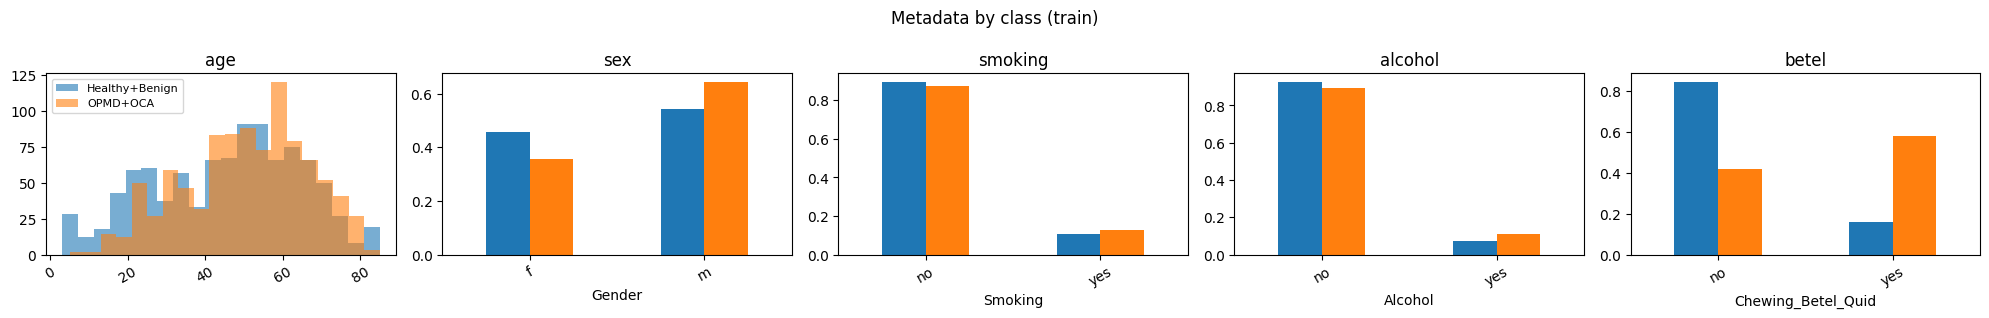

Loaded 3000 images in 306s


In [4]:
# ---------------- encode metadata (fitted on TRAIN only) ----------------
train_mask = (df.split == "train").values
ENC = {"numeric": {}, "categorical": {}}
feat_cols = []
for k, c in cols.items():
    s = df[c]
    num = pd.to_numeric(s, errors="coerce")
    if k == "age" or (num.notna().mean() > 0.9 and s.nunique() > 10):
        med = float(num[train_mask].median()); lo, hi = float(num[train_mask].min()), float(num[train_mask].max())
        df[f"m_{k}"] = ((num.fillna(med) - lo) / max(hi - lo, 1e-6)).clip(0, 1)
        ENC["numeric"][c] = dict(median=med, min=lo, max=hi); feat_cols.append(f"m_{k}")
    else:
        v = s.astype(str).str.strip().str.lower().replace({"nan": "unknown", "": "unknown"})
        cats = sorted(v[train_mask].unique().tolist())
        ENC["categorical"][c] = cats
        for cat in cats:
            df[f"m_{k}={cat}"] = (v == cat).astype(float); feat_cols.append(f"m_{k}={cat}")
META_DIM = len(feat_cols)
print(f"Metadata vector size: {META_DIM}  ->", feat_cols)

M = {s: df.loc[df.split == s, feat_cols].values.astype(np.float32) for s in ("train", "val", "test")}
Y = {s: df.loc[df.split == s, "label"].values.astype(np.int64) for s in ("train", "val", "test")}
PATHS = {s: df.loc[df.split == s, "path"].tolist() for s in ("train", "val", "test")}
SOURCE = {s: df.loc[df.split == s, "source"].values for s in ("train", "val", "test")}

fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.2), squeeze=False)
tr = df[df.split == "train"]
for a, (k, c) in zip(axes[0], cols.items()):
    if c in ENC["numeric"]:
        for i, cl in enumerate(CLASSES):
            a.hist(pd.to_numeric(tr[tr.label == i][c], errors="coerce").dropna(), bins=20, alpha=.6, label=cl)
    else:
        pd.crosstab(tr[c].astype(str).str.lower(), tr.cls, normalize="columns").plot.bar(ax=a, legend=False)
    a.set_title(k); a.tick_params(axis="x", rotation=30)
axes[0][0].legend(fontsize=8); fig.suptitle("Metadata by class (train)"); plt.tight_layout()
fig.savefig(PLOT_DIR / "comparison" / "00_metadata_by_class.png", dpi=120); plt.show()

# ---------------- images into memory ----------------
PRE = 256
def load_one(p):
    return np.asarray(Image.open(p).convert("RGB").resize((PRE, PRE), Image.BICUBIC))
t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    IMGS = {s: np.stack(list(ex.map(load_one, PATHS[s]))) for s in ("train", "val", "test")}
print(f"Loaded {sum(len(v) for v in IMGS.values())} images in {time.time() - t0:.0f}s")
cnt = np.bincount(Y["train"], minlength=2)
CLASS_WEIGHTS = torch.tensor(len(Y["train"]) / (2 * cnt), dtype=torch.float32)


class DS(Dataset):
    def __init__(self, s, tf):
        self.s, self.tf = s, tf
    def __len__(self):
        return len(Y[self.s])
    def __getitem__(self, i):
        return self.tf(Image.fromarray(IMGS[self.s][i])), torch.from_numpy(M[self.s][i]), Y[self.s][i]


def make_tf(mean, std):
    tr = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomHorizontalFlip(), T.RandomAffine(degrees=15, scale=(0.9, 1.1)),
                    T.ColorJitter(contrast=0.1), T.ToTensor(), T.Normalize(mean, std)])
    ev = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(mean, std)])
    return tr, ev

## 4. Models: image only, E1 concat, E2 gated (FiLM)

In [5]:
class FusionNet(nn.Module):
    def __init__(self, timm_id, method, meta_dim):
        super().__init__()
        self.method = method
        self.backbone = timm.create_model(timm_id, pretrained=True, num_classes=0)
        self.backbone.eval()
        with torch.no_grad():                              # real output size (MobileNetV3/V4 add a conv head after pooling)
            f = self.backbone(torch.zeros(1, 3, 96, 96)).shape[1]
        if method == "Image only":
            self.head = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(f, 2))
        elif method == "E1 Concat":                       # paper style: 128 image + 32 metadata features
            self.img_proj = nn.Sequential(nn.Linear(f, 128), nn.GELU())
            self.meta_proj = nn.Sequential(nn.Linear(meta_dim, 32), nn.GELU())
            self.head = nn.Sequential(nn.Linear(160, 64), nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(64, 2))
        elif method == "E2 Gated (FiLM)":                 # metadata -> per-feature scale and shift of the image features
            self.film = nn.Sequential(nn.Linear(meta_dim, 64), nn.GELU(), nn.Linear(64, 2 * f))
            nn.init.zeros_(self.film[-1].weight); nn.init.zeros_(self.film[-1].bias)   # starts as "no modulation"
            self.head = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(f, 2))
        else:
            raise ValueError(method)

    def forward(self, x, m):
        h = self.backbone(x)
        if self.method == "E1 Concat":
            return self.head(torch.cat([self.img_proj(h), self.meta_proj(m)], 1))
        if self.method == "E2 Gated (FiLM)":
            g, b = self.film(m).chunk(2, 1)
            h = h * (1 + torch.tanh(g)) + b
        return self.head(h)


class NonFinite(RuntimeError):
    pass


@torch.no_grad()
def predict(model, loader):
    model.eval(); P = []
    for x, m, _ in loader:
        P.append(model(x.to(DEVICE), m.to(DEVICE)).float().softmax(1)[:, 1].cpu())
    P = torch.cat(P).numpy()
    if not np.isfinite(P).all():
        raise NonFinite("NaN outputs")
    return P


def metrics(y, p1, thr=0.5):
    pred = (p1 >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    return {k: float(v) for k, v in dict(
        accuracy=accuracy_score(y, pred), macro_precision=pr.mean(), macro_recall=rc.mean(),
        macro_f1=f1_score(y, pred, average="macro"), mcc=matthews_corrcoef(y, pred),
        balanced_accuracy=balanced_accuracy_score(y, pred), roc_auc=roc_auc_score(y, p1),
        sensitivity_OPMD_OCA=rc[1], specificity_Benign=rc[0]).items()}, confusion_matrix(y, pred, labels=[0, 1])


def train_nn(spec, method, use_amp):
    seed_everything(SEED)
    model = FusionNet(spec["timm_id"], method, META_DIM).to(DEVICE)
    cfg = timm.data.resolve_model_data_config(model.backbone); mean, std = cfg["mean"], cfg["std"]
    tf_tr, tf_ev = make_tf(mean, std)
    g = torch.Generator().manual_seed(SEED)
    dl_tr = DataLoader(DS("train", tf_tr), BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=g, pin_memory=True)
    dl_va = DataLoader(DS("val", tf_ev), 64, num_workers=NUM_WORKERS)
    body = list(model.backbone.parameters()); bid = {id(p) for p in body}
    rest = [p for p in model.parameters() if id(p) not in bid]
    crit = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE), label_smoothing=LABEL_SMOOTHING)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    def new_phase(phase):
        for p in body:
            p.requires_grad_(phase == 2)
        opt = torch.optim.Adam(rest if phase == 1 else rest + body, lr=PHASE1_LR if phase == 1 else PHASE2_LR)
        return opt, torch.optim.lr_scheduler.ReduceLROnPlateau(opt, "min", PLATEAU_FACTOR, PLATEAU_PATIENCE, min_lr=1e-7)

    opt, sch = new_phase(1)
    hist, best, best_state, bad, t0 = [], -2.0, None, 0, time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        if ep == PHASE1_EPOCHS + 1:
            opt, sch = new_phase(2)
        phase = 1 if ep <= PHASE1_EPOCHS else 2
        model.train()
        if phase == 1:
            for mod in model.backbone.modules():
                if isinstance(mod, nn.modules.batchnorm._BatchNorm):
                    mod.eval()
        tl = tc = tn = 0
        for x, m, y in dl_tr:
            x, m, y = x.to(DEVICE, non_blocking=True), m.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                out = model(x, m); loss = crit(out.float(), y)
            if not torch.isfinite(loss):
                raise NonFinite(f"loss {loss.item()} at epoch {ep}")
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pv = predict(model, dl_va)
        vl = F.cross_entropy(torch.tensor(np.log(np.stack([1 - pv, pv], 1) + 1e-8)), torch.tensor(Y["val"])).item()
        mv, _ = metrics(Y["val"], pv); sch.step(vl)
        hist.append(dict(epoch=ep, phase=phase, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=mv["accuracy"],
                         val_mcc=mv["mcc"], val_macro_f1=mv["macro_f1"], lr=opt.param_groups[0]["lr"]))
        if mv["mcc"] > best:
            best, bad = mv["mcc"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        print(f"  ep {ep:3d} [p{phase}] train loss {tl / tn:.3f} acc {tc / tn:.3f} | val loss {vl:.3f} acc {mv['accuracy']:.3f} "
              f"MCC {mv['mcc']:.3f} F1 {mv['macro_f1']:.3f}{'  *' if bad == 0 else ''}")
        if ep >= MIN_EPOCHS and bad >= PATIENCE:
            print(f"  early stop at epoch {ep} (best val MCC {best:.3f})"); break
    model.load_state_dict(best_state)
    probs = {s: predict(model, DataLoader(DS(s, tf_ev), 64, num_workers=NUM_WORKERS)) for s in ("val", "test")}
    return model, pd.DataFrame(hist), probs, dict(mean=list(mean), std=list(std)), (time.time() - t0) / 60

## 5. Plot helpers

In [6]:
def plot_curves(h, title, path):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("Loss")
    ax[1].plot(h.epoch, h.train_acc, label="train (augmented)"); ax[1].plot(h.epoch, h.val_acc, label="val"); ax[1].set_title("Accuracy")
    ax[2].plot(h.epoch, h.val_mcc, label="val MCC"); ax[2].plot(h.epoch, h.val_macro_f1, label="val macro-F1")
    b = h.val_mcc.idxmax(); ax[2].axvline(h.epoch[b], ls="--", c="gray", lw=1, label=f"best epoch {h.epoch[b]}"); ax[2].set_title("Validation")
    for a in ax:
        a.axvline(PHASE1_EPOCHS + .5, c="k", ls=":", lw=.8); a.grid(alpha=.3); a.legend(fontsize=8); a.set_xlabel("epoch")
    fig.suptitle(title); plt.tight_layout(); fig.savefig(path, dpi=110); plt.show()


def plot_cm(cm, title, path):
    fig, ax = plt.subplots(figsize=(4.2, 3.8)); Mn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(Mn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({Mn[i, j]:.2f})", ha="center", va="center", color="white" if Mn[i, j] > .5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(CLASSES); ax.set_yticks([0, 1]); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=9); plt.tight_layout(); fig.savefig(path, dpi=110); plt.show()

## 6. Metadata-only model (XGBoost)

-> -                  Metadata only          val MCC 0.454 | TEST acc 0.711 MCC 0.433 F1 0.711 AUC 0.800 | cleared Healthy 75% Benign 81% | caught OPMD 65% OCA 65%


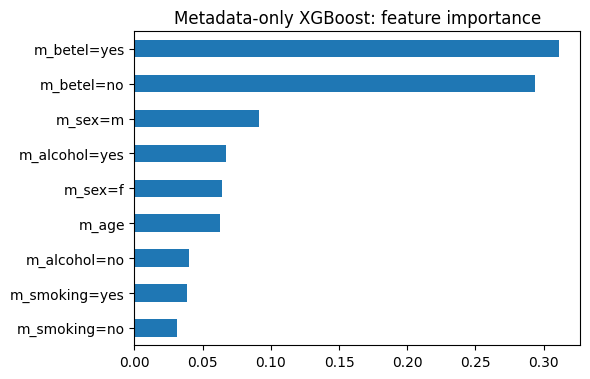

In [7]:
xgb_params = dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  scale_pos_weight=float(cnt[0] / cnt[1]), eval_metric="logloss", random_state=SEED)
meta_model = xgb.XGBClassifier(**xgb_params).fit(M["train"], Y["train"])
META_P = {s: meta_model.predict_proba(M[s])[:, 1] for s in ("val", "test")}
(MODEL_DIR / "Metadata_only").mkdir(parents=True, exist_ok=True)
meta_model.save_model(str(MODEL_DIR / "Metadata_only" / "xgboost.json"))
json.dump(dict(features=feat_cols, columns=cols, encoding=ENC), open(MODEL_DIR / "metadata_encoding.json", "w"), indent=2)

RESULTS, PROBS, CMS = [], {}, {}
def record(backbone, method, group, probs, extra=None):
    row = dict(backbone=backbone, method=method, group=group, **(extra or {}))
    for s in ("val", "test"):
        m, cm = metrics(Y[s], probs[s]); row.update({f"{s}_{k}": v for k, v in m.items()}); CMS[(backbone, method, s)] = cm
    src = SOURCE["test"]; pred_t = (probs["test"] >= 0.5).astype(int)
    for f in ("Healthy", "Benign", "OPMD", "OCA"):                     # share of each original class predicted correctly
        sel = src == f
        if sel.any():
            row[f"test_{f}_correct"] = float((pred_t[sel] == (0 if f in ("Healthy", "Benign") else 1)).mean())
    PROBS[(backbone, method)] = probs; RESULTS.append(row)
    print(f"-> {backbone:18s} {method:22s} val MCC {row['val_mcc']:.3f} | TEST acc {row['test_accuracy']:.3f} "
          f"MCC {row['test_mcc']:.3f} F1 {row['test_macro_f1']:.3f} AUC {row['test_roc_auc']:.3f} | cleared Healthy "
          f"{row.get('test_Healthy_correct', 0):.0%} Benign {row.get('test_Benign_correct', 0):.0%} | caught OPMD "
          f"{row.get('test_OPMD_correct', 0):.0%} OCA {row.get('test_OCA_correct', 0):.0%}")
    return row

record("-", "Metadata only", "Baseline", META_P)
imp = pd.Series(meta_model.feature_importances_, index=feat_cols).sort_values()
fig, ax = plt.subplots(figsize=(6, 0.3 * len(imp) + 1.2)); imp.plot.barh(ax=ax); ax.set_title("Metadata-only XGBoost: feature importance")
plt.tight_layout(); fig.savefig(PLOT_DIR / "comparison" / "01_metadata_importance.png", dpi=120); plt.show()

## 7. Train image-only, E1 and E2 for every backbone, then late fusion L1-L4


MobileNetV2 | Image only


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep   1 [p1] train loss 0.692 acc 0.570 | val loss 0.638 acc 0.631 MCC 0.327 F1 0.606  *
  ep   2 [p1] train loss 0.656 acc 0.627 | val loss 0.645 acc 0.609 MCC 0.323 F1 0.564
  ep   3 [p1] train loss 0.642 acc 0.640 | val loss 0.607 acc 0.673 MCC 0.383 F1 0.664  *
  ep   4 [p1] train loss 0.637 acc 0.652 | val loss 0.586 acc 0.692 MCC 0.388 F1 0.688  *
  ep   5 [p1] train loss 0.630 acc 0.675 | val loss 0.590 acc 0.691 MCC 0.406 F1 0.686  *
  ep   6 [p1] train loss 0.627 acc 0.678 | val loss 0.576 acc 0.714 MCC 0.428 F1 0.712  *
  ep   7 [p1] train loss 0.633 acc 0.659 | val loss 0.578 acc 0.704 MCC 0.407 F1 0.704
  ep   8 [p1] train loss 0.617 acc 0.688 | val loss 0.578 acc 0.691 MCC 0.387 F1 0.690
  ep   9 [p1] train loss 0.624 acc 0.688 | val loss 0.578 acc 0.706 MCC 0.414 F1 0.706
  ep  10 [p1] train loss 0.611 acc 0.685 | val loss 0.579 acc 0.702 MCC 0.408 F1 0.702
  ep  11 [p2] train loss 0.699 acc 0.620 | val loss 0.612 acc 0.652 MCC 0.304 F1 0.652
  ep  12 [p2] train loss 0.6

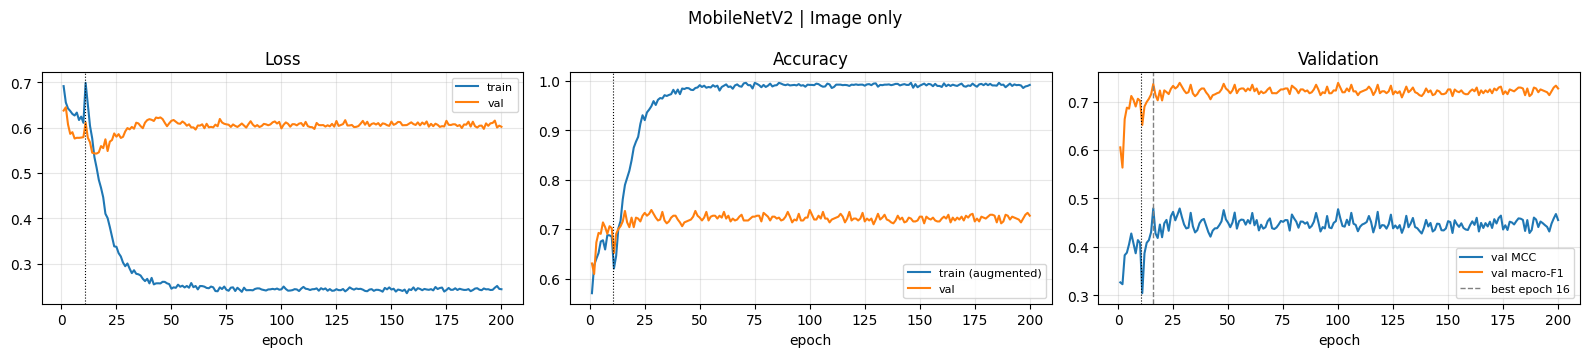

-> MobileNetV2        Image only             val MCC 0.480 | TEST acc 0.669 MCC 0.355 F1 0.669 AUC 0.740 | cleared Healthy 80% Benign 73% | caught OPMD 61% OCA 46%


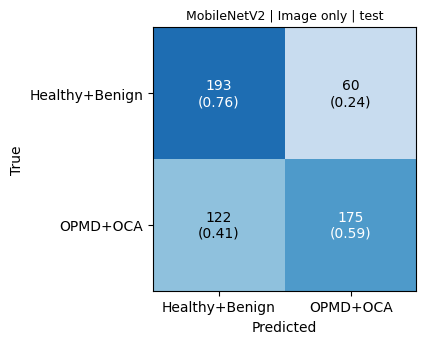

-> MobileNetV2        L1 Simple average      val MCC 0.574 | TEST acc 0.747 MCC 0.508 F1 0.747 AUC 0.830 | cleared Healthy 88% Benign 78% | caught OPMD 70% OCA 54%
-> MobileNetV2        L2 Weighted average    val MCC 0.586 | TEST acc 0.756 MCC 0.528 F1 0.756 AUC 0.835 | cleared Healthy 89% Benign 80% | caught OPMD 70% OCA 54%
-> MobileNetV2        L3 Stacking (LogReg)   val MCC 0.571 | TEST acc 0.738 MCC 0.493 F1 0.738 AUC 0.828 | cleared Healthy 88% Benign 78% | caught OPMD 69% OCA 43%
-> MobileNetV2        L4 Stacking (XGBoost)  val MCC 0.621 | TEST acc 0.725 MCC 0.462 F1 0.725 AUC 0.804 | cleared Healthy 86% Benign 73% | caught OPMD 65% OCA 81%

MobileNetV2 | E1 Concat
  ep   1 [p1] train loss 0.664 acc 0.603 | val loss 0.603 acc 0.681 MCC 0.423 F1 0.665  *
  ep   2 [p1] train loss 0.585 acc 0.723 | val loss 0.575 acc 0.700 MCC 0.456 F1 0.688  *
  ep   3 [p1] train loss 0.557 acc 0.736 | val loss 0.504 acc 0.754 MCC 0.518 F1 0.754  *
  ep   4 [p1] train loss 0.546 acc 0.754 | val lo

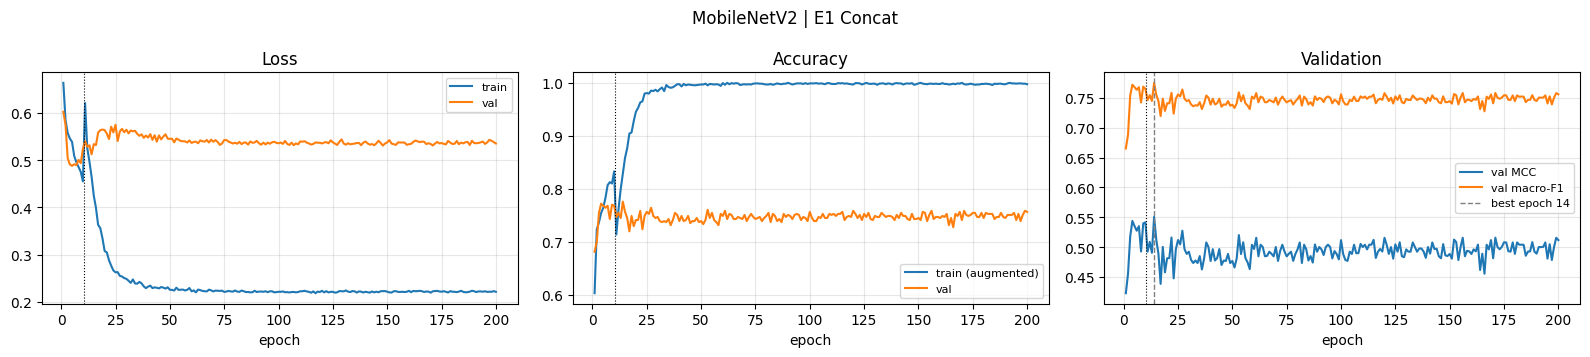

-> MobileNetV2        E1 Concat              val MCC 0.551 | TEST acc 0.747 MCC 0.500 F1 0.747 AUC 0.821 | cleared Healthy 82% Benign 76% | caught OPMD 69% OCA 84%


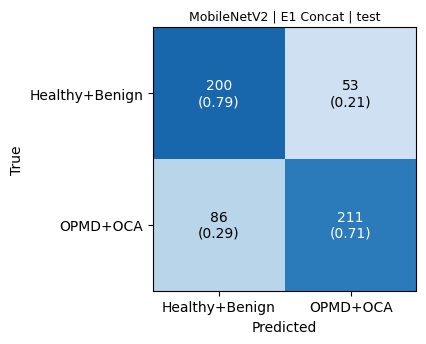


MobileNetV2 | E2 Gated (FiLM)
  ep   1 [p1] train loss 0.630 acc 0.682 | val loss 0.558 acc 0.741 MCC 0.503 F1 0.738  *
  ep   2 [p1] train loss 0.586 acc 0.727 | val loss 0.545 acc 0.764 MCC 0.543 F1 0.763  *
  ep   3 [p1] train loss 0.573 acc 0.733 | val loss 0.506 acc 0.772 MCC 0.549 F1 0.772  *
  ep   4 [p1] train loss 0.566 acc 0.746 | val loss 0.514 acc 0.774 MCC 0.547 F1 0.773
  ep   5 [p1] train loss 0.563 acc 0.740 | val loss 0.496 acc 0.781 MCC 0.563 F1 0.781  *
  ep   6 [p1] train loss 0.555 acc 0.744 | val loss 0.537 acc 0.774 MCC 0.549 F1 0.772
  ep   7 [p1] train loss 0.553 acc 0.743 | val loss 0.508 acc 0.776 MCC 0.551 F1 0.775
  ep   8 [p1] train loss 0.539 acc 0.767 | val loss 0.503 acc 0.772 MCC 0.547 F1 0.772
  ep   9 [p1] train loss 0.543 acc 0.764 | val loss 0.516 acc 0.754 MCC 0.510 F1 0.752
  ep  10 [p1] train loss 0.535 acc 0.770 | val loss 0.512 acc 0.772 MCC 0.543 F1 0.771
  ep  11 [p2] train loss 0.586 acc 0.731 | val loss 0.542 acc 0.754 MCC 0.508 F1 0.754


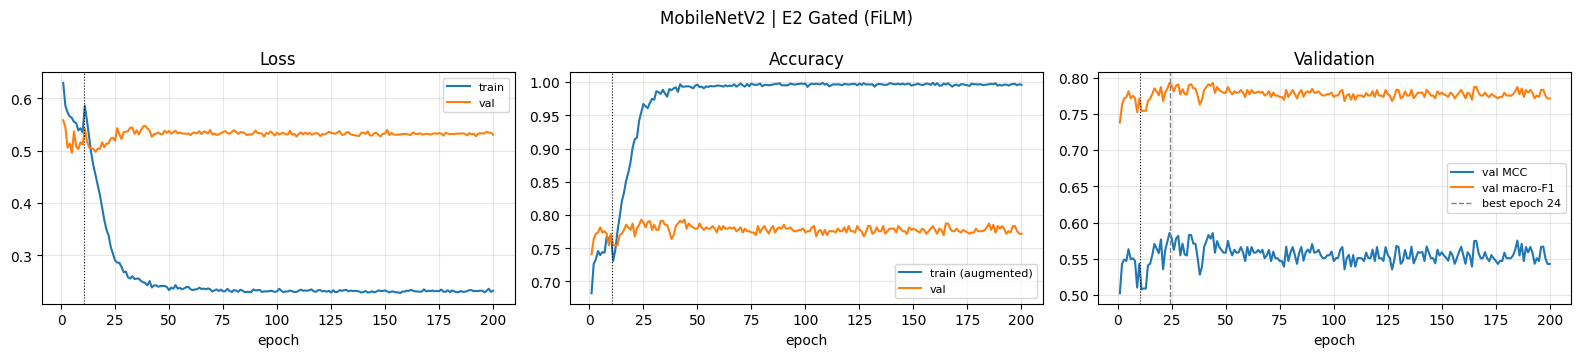

-> MobileNetV2        E2 Gated (FiLM)        val MCC 0.586 | TEST acc 0.756 MCC 0.522 F1 0.756 AUC 0.827 | cleared Healthy 87% Benign 77% | caught OPMD 71% OCA 65%


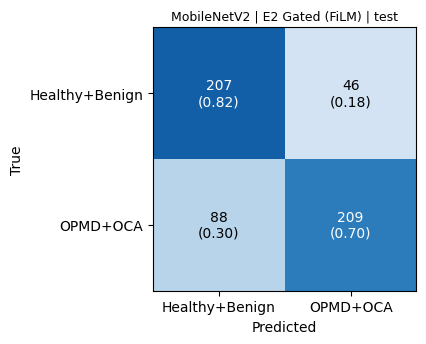


MobileNetV4-Conv-S | Image only


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep   1 [p1] train loss 0.687 acc 0.565 | val loss 0.646 acc 0.640 MCC 0.323 F1 0.626  *
  ep   2 [p1] train loss 0.658 acc 0.610 | val loss 0.653 acc 0.607 MCC 0.288 F1 0.573
  ep   3 [p1] train loss 0.638 acc 0.641 | val loss 0.628 acc 0.656 MCC 0.353 F1 0.643  *
  ep   4 [p1] train loss 0.637 acc 0.656 | val loss 0.608 acc 0.660 MCC 0.325 F1 0.651
  ep   5 [p1] train loss 0.625 acc 0.666 | val loss 0.611 acc 0.667 MCC 0.356 F1 0.662  *
  ep   6 [p1] train loss 0.621 acc 0.670 | val loss 0.600 acc 0.694 MCC 0.388 F1 0.693  *
  ep   7 [p1] train loss 0.623 acc 0.673 | val loss 0.603 acc 0.665 MCC 0.334 F1 0.665
  ep   8 [p1] train loss 0.614 acc 0.677 | val loss 0.592 acc 0.691 MCC 0.381 F1 0.690
  ep   9 [p1] train loss 0.623 acc 0.672 | val loss 0.600 acc 0.660 MCC 0.338 F1 0.655
  ep  10 [p1] train loss 0.617 acc 0.672 | val loss 0.591 acc 0.694 MCC 0.401 F1 0.693  *
  ep  11 [p2] train loss 0.750 acc 0.573 | val loss 0.606 acc 0.656 MCC 0.310 F1 0.654
  ep  12 [p2] train loss 0.6

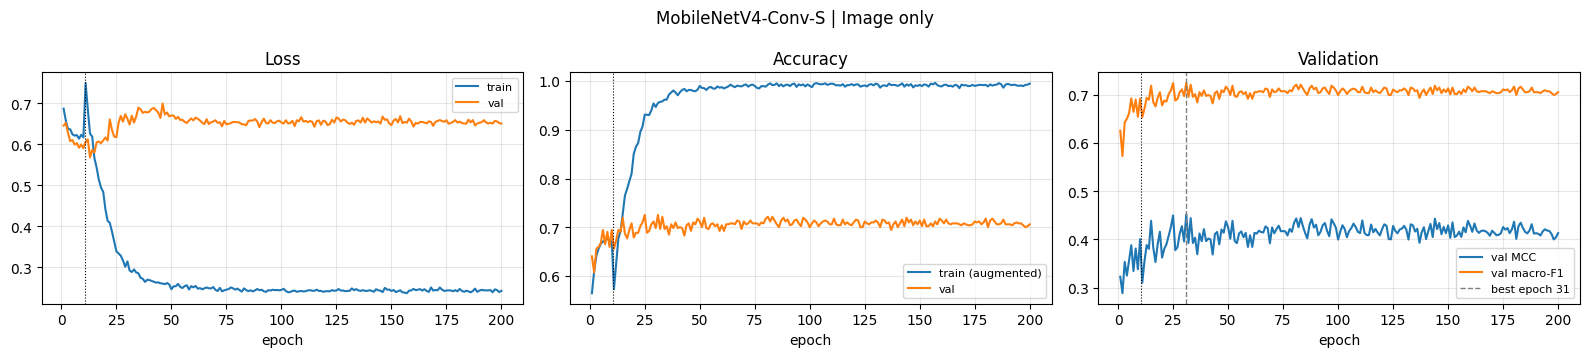

-> MobileNetV4-Conv-S Image only             val MCC 0.452 | TEST acc 0.684 MCC 0.373 F1 0.684 AUC 0.765 | cleared Healthy 78% Benign 67% | caught OPMD 65% OCA 65%


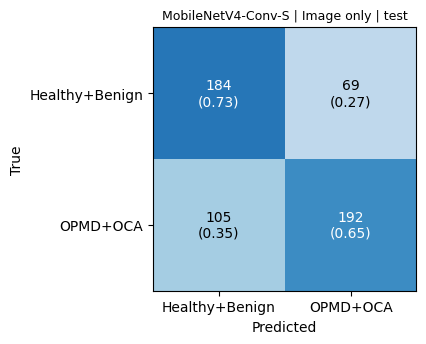

-> MobileNetV4-Conv-S L1 Simple average      val MCC 0.520 | TEST acc 0.731 MCC 0.469 F1 0.731 AUC 0.830 | cleared Healthy 86% Benign 70% | caught OPMD 69% OCA 65%
-> MobileNetV4-Conv-S L2 Weighted average    val MCC 0.559 | TEST acc 0.747 MCC 0.501 F1 0.747 AUC 0.835 | cleared Healthy 86% Benign 74% | caught OPMD 72% OCA 57%
-> MobileNetV4-Conv-S L3 Stacking (LogReg)   val MCC 0.540 | TEST acc 0.722 MCC 0.456 F1 0.722 AUC 0.838 | cleared Healthy 86% Benign 73% | caught OPMD 67% OCA 54%
-> MobileNetV4-Conv-S L4 Stacking (XGBoost)  val MCC 0.627 | TEST acc 0.758 MCC 0.523 F1 0.758 AUC 0.817 | cleared Healthy 86% Benign 76% | caught OPMD 68% OCA 92%

MobileNetV4-Conv-S | E1 Concat
  ep   1 [p1] train loss 0.662 acc 0.594 | val loss 0.611 acc 0.642 MCC 0.361 F1 0.616  *
  ep   2 [p1] train loss 0.590 acc 0.719 | val loss 0.535 acc 0.760 MCC 0.526 F1 0.760  *
  ep   3 [p1] train loss 0.561 acc 0.743 | val loss 0.536 acc 0.743 MCC 0.497 F1 0.742
  ep   4 [p1] train loss 0.549 acc 0.753 | va

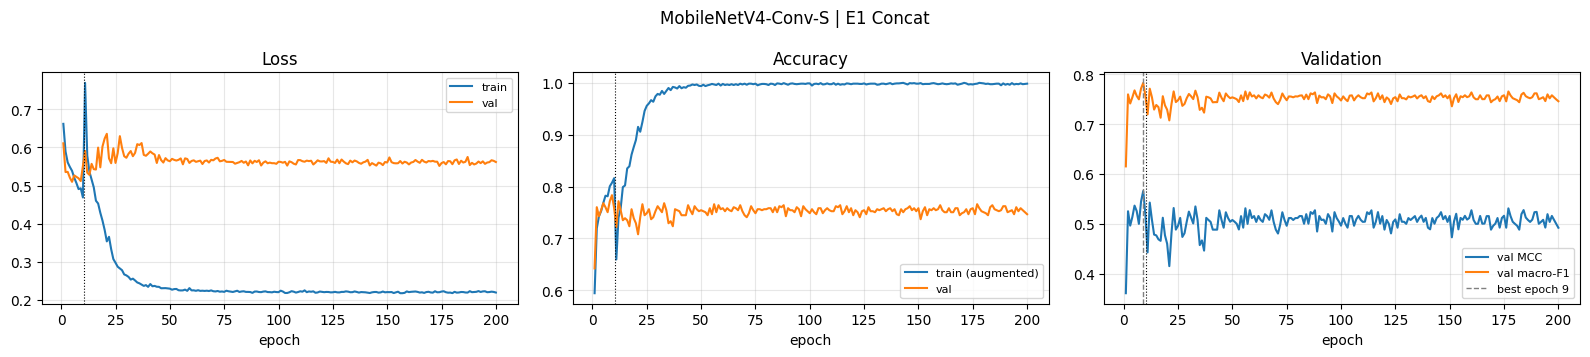

-> MobileNetV4-Conv-S E1 Concat              val MCC 0.566 | TEST acc 0.718 MCC 0.441 F1 0.718 AUC 0.810 | cleared Healthy 81% Benign 71% | caught OPMD 65% OCA 89%


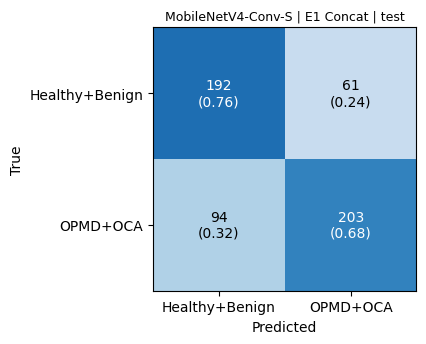


MobileNetV4-Conv-S | E2 Gated (FiLM)
  ep   1 [p1] train loss 0.632 acc 0.676 | val loss 0.553 acc 0.739 MCC 0.489 F1 0.738  *
  ep   2 [p1] train loss 0.589 acc 0.721 | val loss 0.542 acc 0.747 MCC 0.504 F1 0.746  *
  ep   3 [p1] train loss 0.568 acc 0.736 | val loss 0.525 acc 0.762 MCC 0.529 F1 0.762  *
  ep   4 [p1] train loss 0.570 acc 0.729 | val loss 0.533 acc 0.770 MCC 0.539 F1 0.770  *
  ep   5 [p1] train loss 0.557 acc 0.753 | val loss 0.524 acc 0.758 MCC 0.521 F1 0.758
  ep   6 [p1] train loss 0.550 acc 0.750 | val loss 0.547 acc 0.774 MCC 0.547 F1 0.773  *
  ep   7 [p1] train loss 0.553 acc 0.751 | val loss 0.534 acc 0.754 MCC 0.508 F1 0.754
  ep   8 [p1] train loss 0.535 acc 0.769 | val loss 0.522 acc 0.772 MCC 0.547 F1 0.772
  ep   9 [p1] train loss 0.556 acc 0.744 | val loss 0.513 acc 0.778 MCC 0.555 F1 0.777  *
  ep  10 [p1] train loss 0.540 acc 0.756 | val loss 0.529 acc 0.785 MCC 0.571 F1 0.784  *
  ep  11 [p2] train loss 0.617 acc 0.714 | val loss 0.549 acc 0.747 MCC

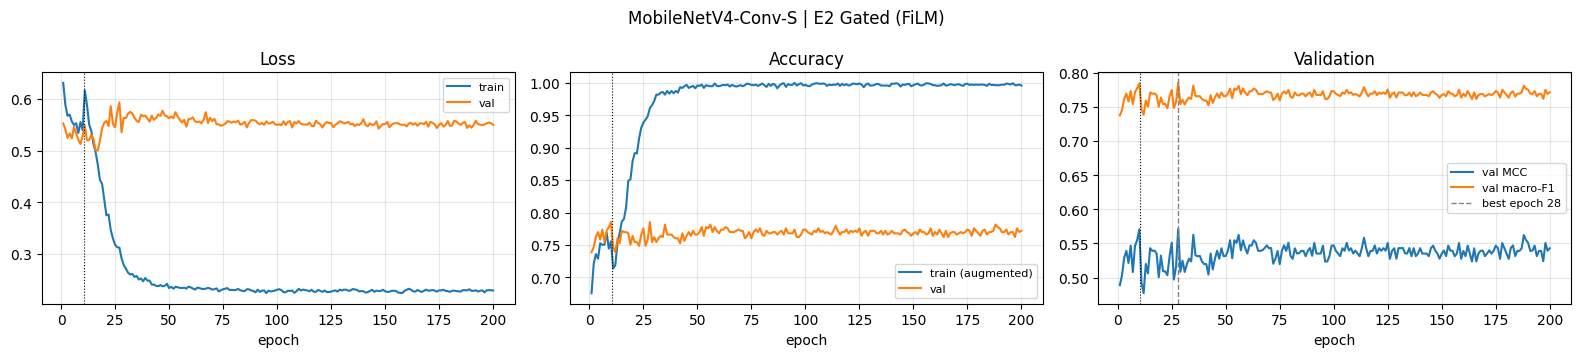

-> MobileNetV4-Conv-S E2 Gated (FiLM)        val MCC 0.572 | TEST acc 0.775 MCC 0.560 F1 0.775 AUC 0.848 | cleared Healthy 90% Benign 79% | caught OPMD 70% OCA 84%


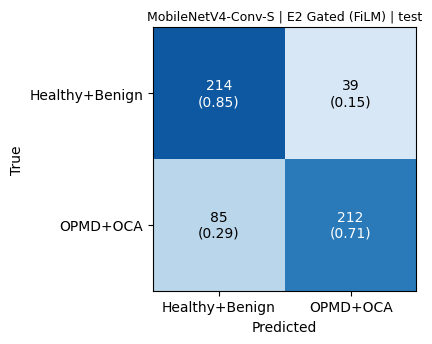


EfficientNet-B0 | Image only


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep   1 [p1] train loss 0.692 acc 0.577 | val loss 0.635 acc 0.646 MCC 0.336 F1 0.632  *
  ep   2 [p1] train loss 0.643 acc 0.651 | val loss 0.615 acc 0.675 MCC 0.378 F1 0.668  *
  ep   3 [p1] train loss 0.627 acc 0.658 | val loss 0.616 acc 0.675 MCC 0.381 F1 0.668  *
  ep   4 [p1] train loss 0.617 acc 0.675 | val loss 0.604 acc 0.663 MCC 0.336 F1 0.653
  ep   5 [p1] train loss 0.625 acc 0.666 | val loss 0.596 acc 0.681 MCC 0.374 F1 0.679
  ep   6 [p1] train loss 0.611 acc 0.681 | val loss 0.593 acc 0.689 MCC 0.376 F1 0.688
  ep   7 [p1] train loss 0.602 acc 0.695 | val loss 0.589 acc 0.700 MCC 0.400 F1 0.700  *
  ep   8 [p1] train loss 0.606 acc 0.701 | val loss 0.585 acc 0.679 MCC 0.360 F1 0.679
  ep   9 [p1] train loss 0.599 acc 0.697 | val loss 0.595 acc 0.694 MCC 0.400 F1 0.693  *
  ep  10 [p1] train loss 0.605 acc 0.692 | val loss 0.587 acc 0.694 MCC 0.392 F1 0.694
  ep  11 [p2] train loss 0.691 acc 0.606 | val loss 0.585 acc 0.681 MCC 0.361 F1 0.679
  ep  12 [p2] train loss 0.5

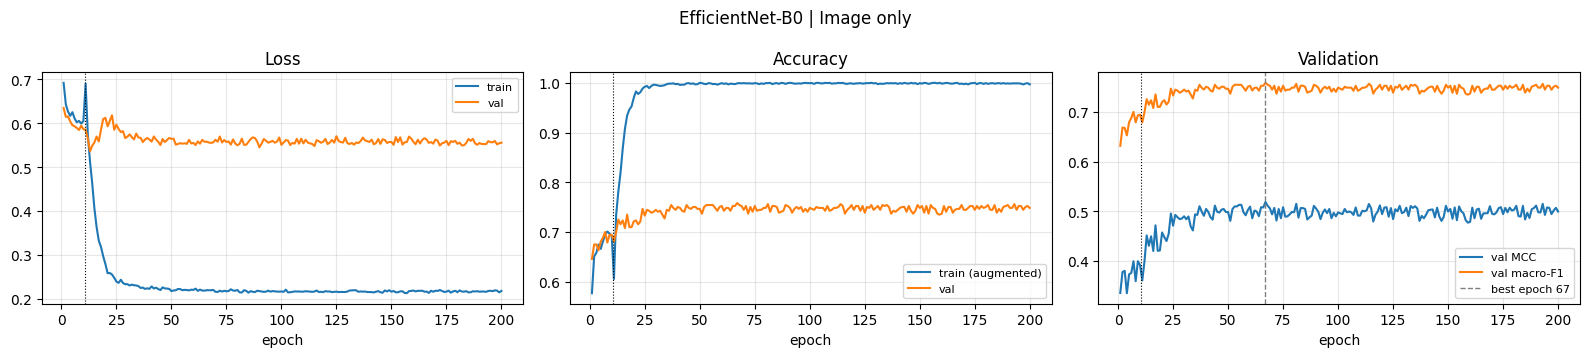

-> EfficientNet-B0    Image only             val MCC 0.519 | TEST acc 0.713 MCC 0.431 F1 0.713 AUC 0.778 | cleared Healthy 82% Benign 70% | caught OPMD 66% OCA 76%


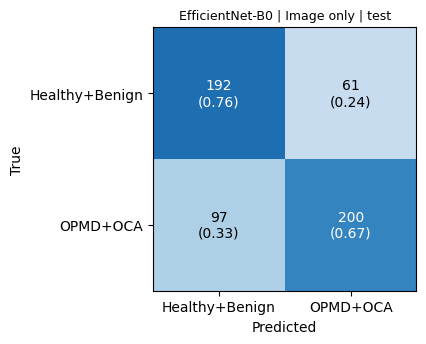

-> EfficientNet-B0    L1 Simple average      val MCC 0.570 | TEST acc 0.762 MCC 0.531 F1 0.762 AUC 0.840 | cleared Healthy 88% Benign 76% | caught OPMD 73% OCA 62%
-> EfficientNet-B0    L2 Weighted average    val MCC 0.594 | TEST acc 0.760 MCC 0.525 F1 0.760 AUC 0.845 | cleared Healthy 86% Benign 74% | caught OPMD 74% OCA 62%
-> EfficientNet-B0    L3 Stacking (LogReg)   val MCC 0.566 | TEST acc 0.756 MCC 0.527 F1 0.756 AUC 0.843 | cleared Healthy 90% Benign 79% | caught OPMD 69% OCA 62%
-> EfficientNet-B0    L4 Stacking (XGBoost)  val MCC 0.601 | TEST acc 0.769 MCC 0.548 F1 0.769 AUC 0.834 | cleared Healthy 91% Benign 76% | caught OPMD 68% OCA 92%

EfficientNet-B0 | E1 Concat
  ep   1 [p1] train loss 0.661 acc 0.603 | val loss 0.608 acc 0.698 MCC 0.448 F1 0.687  *
  ep   2 [p1] train loss 0.586 acc 0.712 | val loss 0.549 acc 0.721 MCC 0.463 F1 0.719  *
  ep   3 [p1] train loss 0.549 acc 0.756 | val loss 0.527 acc 0.739 MCC 0.478 F1 0.739  *
  ep   4 [p1] train loss 0.532 acc 0.768 | va

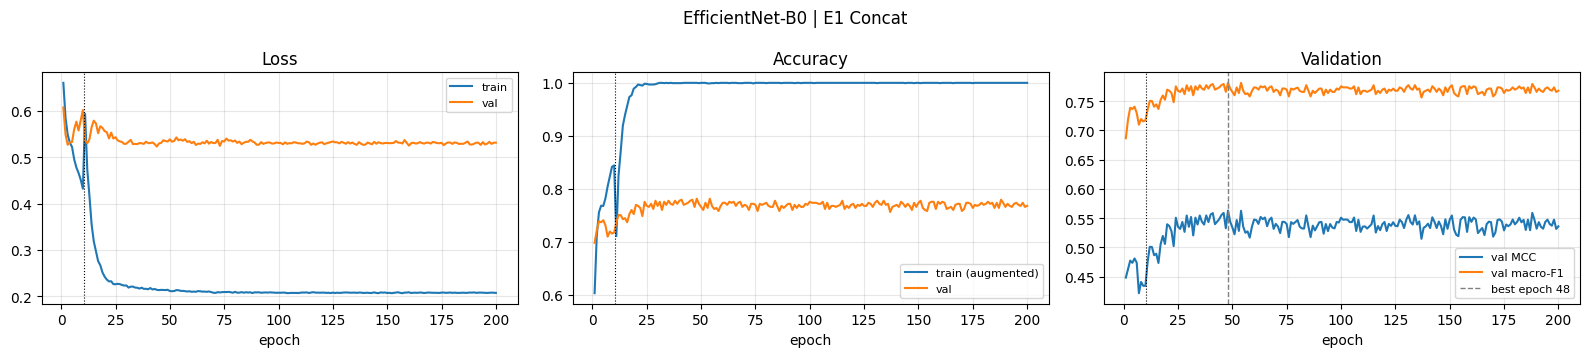

-> EfficientNet-B0    E1 Concat              val MCC 0.563 | TEST acc 0.736 MCC 0.482 F1 0.736 AUC 0.814 | cleared Healthy 85% Benign 75% | caught OPMD 67% OCA 81%


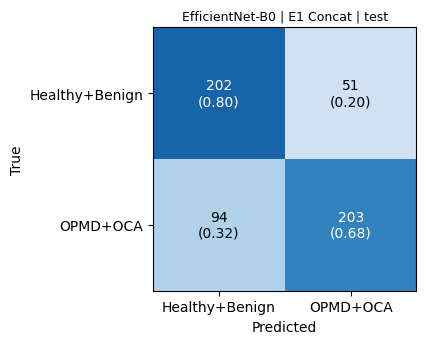


EfficientNet-B0 | E2 Gated (FiLM)
  ep   1 [p1] train loss 0.644 acc 0.667 | val loss 0.554 acc 0.733 MCC 0.482 F1 0.731  *
  ep   2 [p1] train loss 0.584 acc 0.722 | val loss 0.539 acc 0.749 MCC 0.509 F1 0.747  *
  ep   3 [p1] train loss 0.570 acc 0.730 | val loss 0.521 acc 0.754 MCC 0.514 F1 0.754  *
  ep   4 [p1] train loss 0.557 acc 0.735 | val loss 0.544 acc 0.752 MCC 0.508 F1 0.750
  ep   5 [p1] train loss 0.563 acc 0.744 | val loss 0.522 acc 0.754 MCC 0.509 F1 0.754
  ep   6 [p1] train loss 0.543 acc 0.756 | val loss 0.550 acc 0.760 MCC 0.523 F1 0.758  *
  ep   7 [p1] train loss 0.535 acc 0.765 | val loss 0.530 acc 0.754 MCC 0.508 F1 0.753
  ep   8 [p1] train loss 0.534 acc 0.767 | val loss 0.524 acc 0.756 MCC 0.517 F1 0.756
  ep   9 [p1] train loss 0.534 acc 0.755 | val loss 0.526 acc 0.762 MCC 0.524 F1 0.762  *
  ep  10 [p1] train loss 0.530 acc 0.774 | val loss 0.549 acc 0.772 MCC 0.546 F1 0.770  *
  ep  11 [p2] train loss 0.603 acc 0.709 | val loss 0.537 acc 0.762 MCC 0.524

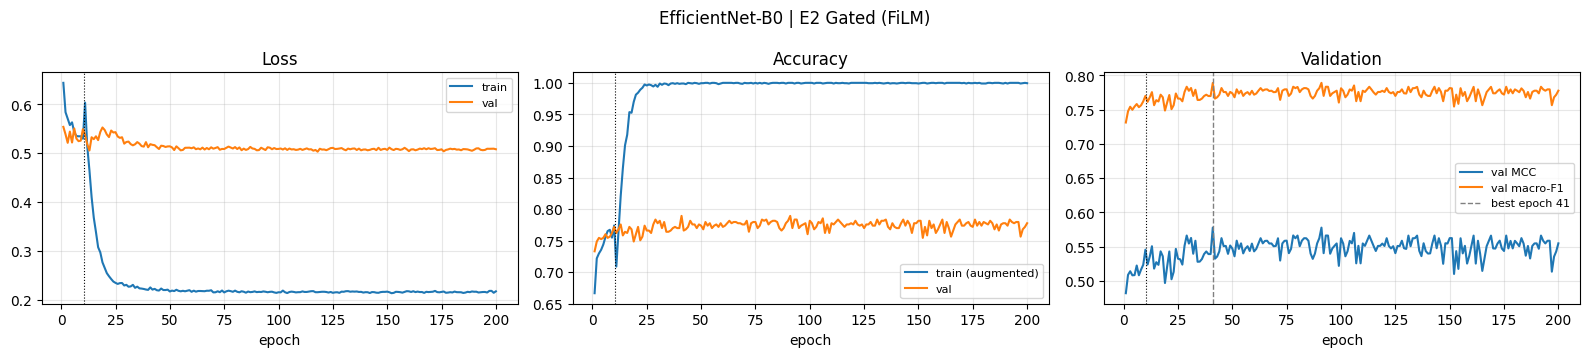

-> EfficientNet-B0    E2 Gated (FiLM)        val MCC 0.578 | TEST acc 0.758 MCC 0.526 F1 0.758 AUC 0.834 | cleared Healthy 87% Benign 77% | caught OPMD 68% OCA 84%


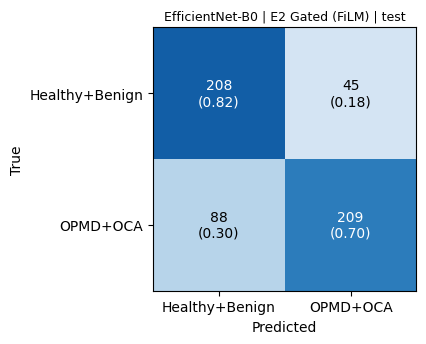


MobileNetV3-Large | Image only


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep   1 [p1] train loss 0.687 acc 0.579 | val loss 0.612 acc 0.669 MCC 0.365 F1 0.663  *
  ep   2 [p1] train loss 0.643 acc 0.654 | val loss 0.613 acc 0.677 MCC 0.391 F1 0.668  *
  ep   3 [p1] train loss 0.639 acc 0.647 | val loss 0.583 acc 0.698 MCC 0.402 F1 0.698  *
  ep   4 [p1] train loss 0.622 acc 0.672 | val loss 0.575 acc 0.710 MCC 0.429 F1 0.703  *
  ep   5 [p1] train loss 0.605 acc 0.691 | val loss 0.563 acc 0.714 MCC 0.432 F1 0.713  *
  ep   6 [p1] train loss 0.616 acc 0.672 | val loss 0.562 acc 0.720 MCC 0.439 F1 0.718  *
  ep   7 [p1] train loss 0.603 acc 0.693 | val loss 0.558 acc 0.721 MCC 0.443 F1 0.721  *
  ep   8 [p1] train loss 0.613 acc 0.691 | val loss 0.559 acc 0.712 MCC 0.424 F1 0.710
  ep   9 [p1] train loss 0.610 acc 0.690 | val loss 0.554 acc 0.714 MCC 0.427 F1 0.713
  ep  10 [p1] train loss 0.610 acc 0.682 | val loss 0.553 acc 0.721 MCC 0.444 F1 0.719  *
  ep  11 [p2] train loss 0.658 acc 0.627 | val loss 0.584 acc 0.702 MCC 0.403 F1 0.701
  ep  12 [p2] train

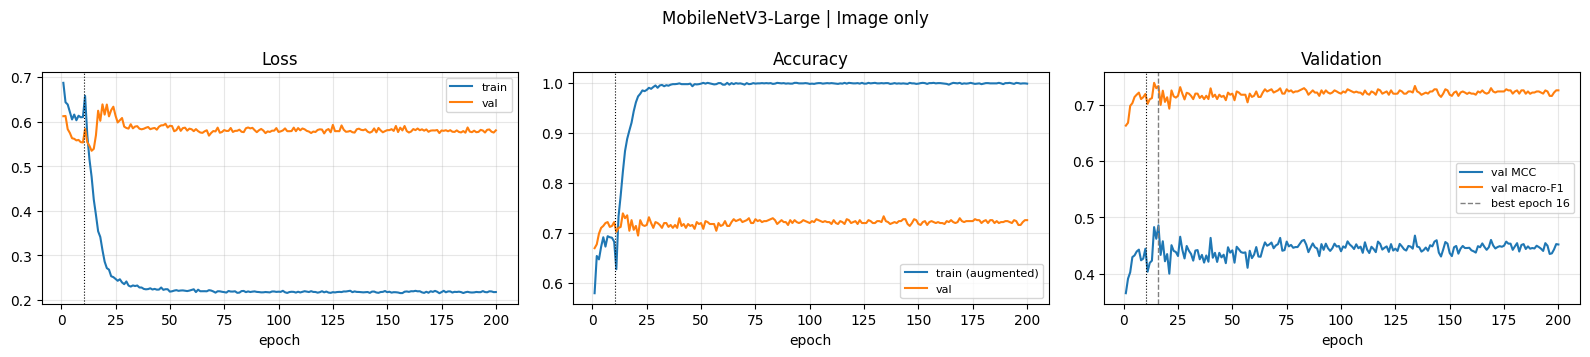

-> MobileNetV3-Large  Image only             val MCC 0.486 | TEST acc 0.684 MCC 0.392 F1 0.683 AUC 0.766 | cleared Healthy 83% Benign 78% | caught OPMD 58% OCA 54%


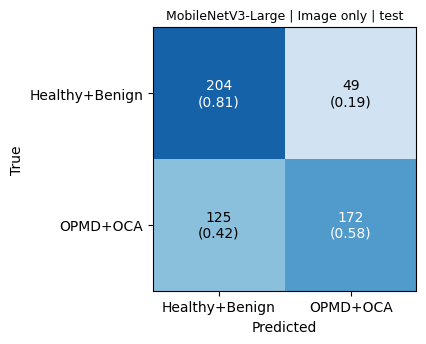

-> MobileNetV3-Large  L1 Simple average      val MCC 0.559 | TEST acc 0.742 MCC 0.498 F1 0.742 AUC 0.837 | cleared Healthy 88% Benign 77% | caught OPMD 68% OCA 59%
-> MobileNetV3-Large  L2 Weighted average    val MCC 0.563 | TEST acc 0.744 MCC 0.500 F1 0.744 AUC 0.840 | cleared Healthy 88% Benign 77% | caught OPMD 69% OCA 57%
-> MobileNetV3-Large  L3 Stacking (LogReg)   val MCC 0.543 | TEST acc 0.760 MCC 0.526 F1 0.760 AUC 0.830 | cleared Healthy 86% Benign 76% | caught OPMD 73% OCA 59%
-> MobileNetV3-Large  L4 Stacking (XGBoost)  val MCC 0.609 | TEST acc 0.729 MCC 0.474 F1 0.729 AUC 0.809 | cleared Healthy 90% Benign 74% | caught OPMD 63% OCA 81%

MobileNetV3-Large | E1 Concat
  ep   1 [p1] train loss 0.658 acc 0.617 | val loss 0.575 acc 0.729 MCC 0.482 F1 0.726  *
  ep   2 [p1] train loss 0.580 acc 0.728 | val loss 0.524 acc 0.747 MCC 0.502 F1 0.746  *
  ep   3 [p1] train loss 0.548 acc 0.757 | val loss 0.521 acc 0.739 MCC 0.487 F1 0.738
  ep   4 [p1] train loss 0.528 acc 0.779 | val

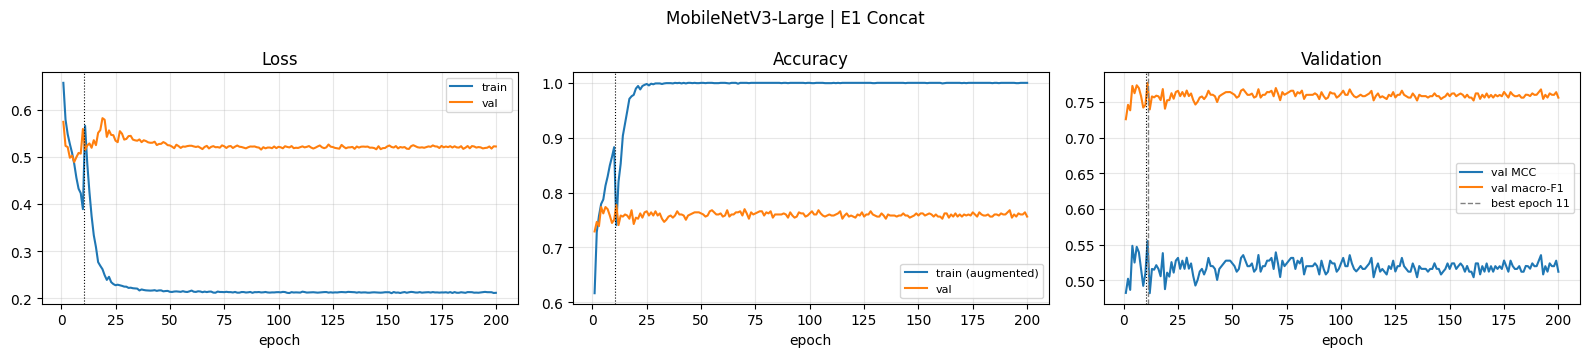

-> MobileNetV3-Large  E1 Concat              val MCC 0.555 | TEST acc 0.744 MCC 0.489 F1 0.743 AUC 0.834 | cleared Healthy 82% Benign 71% | caught OPMD 70% OCA 86%


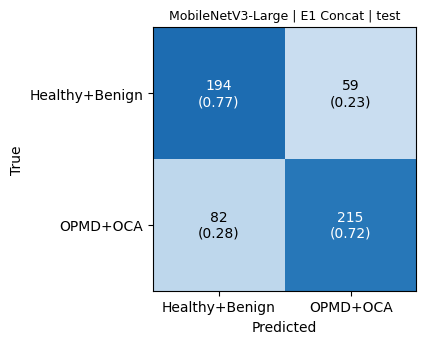


MobileNetV3-Large | E2 Gated (FiLM)
  ep   1 [p1] train loss 0.641 acc 0.669 | val loss 0.556 acc 0.745 MCC 0.507 F1 0.743  *
  ep   2 [p1] train loss 0.572 acc 0.744 | val loss 0.535 acc 0.747 MCC 0.505 F1 0.746
  ep   3 [p1] train loss 0.569 acc 0.733 | val loss 0.506 acc 0.778 MCC 0.557 F1 0.778  *
  ep   4 [p1] train loss 0.550 acc 0.748 | val loss 0.540 acc 0.749 MCC 0.502 F1 0.745
  ep   5 [p1] train loss 0.553 acc 0.760 | val loss 0.497 acc 0.783 MCC 0.566 F1 0.783  *
  ep   6 [p1] train loss 0.542 acc 0.762 | val loss 0.538 acc 0.766 MCC 0.532 F1 0.765
  ep   7 [p1] train loss 0.534 acc 0.767 | val loss 0.507 acc 0.758 MCC 0.516 F1 0.757
  ep   8 [p1] train loss 0.534 acc 0.765 | val loss 0.527 acc 0.770 MCC 0.539 F1 0.770
  ep   9 [p1] train loss 0.534 acc 0.771 | val loss 0.510 acc 0.770 MCC 0.540 F1 0.769
  ep  10 [p1] train loss 0.521 acc 0.779 | val loss 0.529 acc 0.758 MCC 0.522 F1 0.755
  ep  11 [p2] train loss 0.570 acc 0.733 | val loss 0.528 acc 0.770 MCC 0.540 F1 0.7

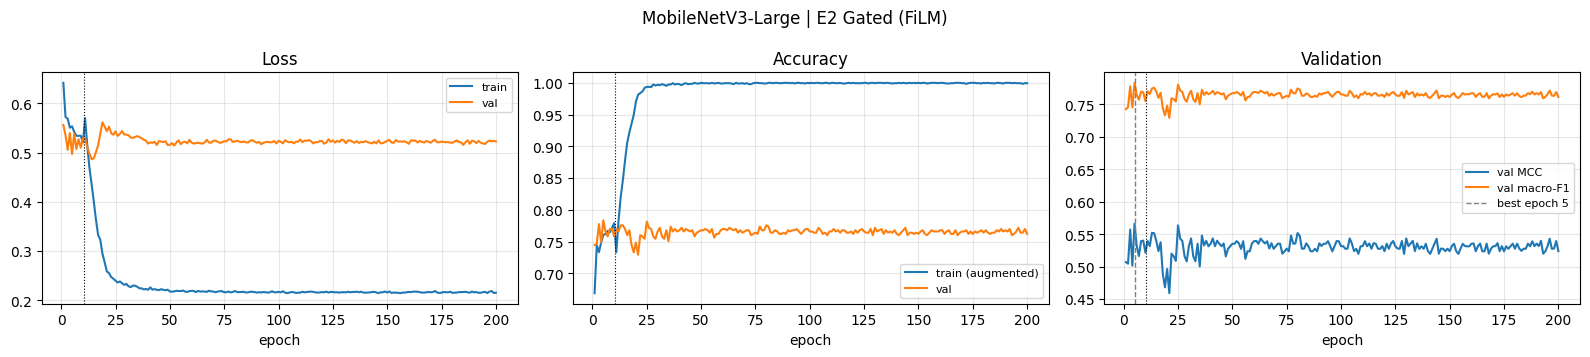

-> MobileNetV3-Large  E2 Gated (FiLM)        val MCC 0.566 | TEST acc 0.758 MCC 0.530 F1 0.758 AUC 0.838 | cleared Healthy 87% Benign 81% | caught OPMD 67% OCA 84%


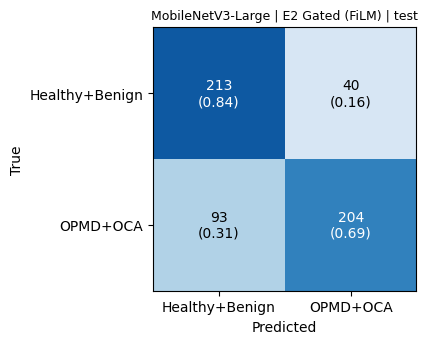

In [8]:
def late_fusion(bb, img_p):
    """L1-L4 from the image-only model's probabilities and the metadata (fitted on VALIDATION; val scores are cross-validated)."""
    yv = Y["val"]
    # L1 simple average
    record(bb, "L1 Simple average", "Late fusion", {s: (img_p[s] + META_P[s]) / 2 for s in ("val", "test")})
    # L2 weighted average, weight chosen on validation by MCC
    ws = np.linspace(0, 1, 21)
    w = ws[int(np.argmax([matthews_corrcoef(yv, ((w_ * img_p["val"] + (1 - w_) * META_P["val"]) >= .5).astype(int)) for w_ in ws]))]
    record(bb, "L2 Weighted average", "Late fusion", {s: w * img_p[s] + (1 - w) * META_P[s] for s in ("val", "test")},
           dict(image_weight=float(w)))
    # L3 stacking: logistic regression on the two logits
    lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    Z = {s: np.stack([lg(img_p[s]), lg(META_P[s])], 1) for s in ("val", "test")}
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    lr = LogisticRegression(class_weight="balanced", max_iter=1000)
    p_val = cross_val_predict(lr, Z["val"], yv, cv=cv, method="predict_proba")[:, 1]
    lr.fit(Z["val"], yv)
    record(bb, "L3 Stacking (LogReg)", "Late fusion", {"val": p_val, "test": lr.predict_proba(Z["test"])[:, 1]})
    # L4 stacking: XGBoost on [image probability + metadata]
    Xs = {s: np.column_stack([img_p[s], M[s]]) for s in ("val", "test")}
    xs = xgb.XGBClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, eval_metric="logloss",
                           scale_pos_weight=float((yv == 0).sum() / (yv == 1).sum()), random_state=SEED)
    p_val4 = cross_val_predict(xs, Xs["val"], yv, cv=cv, method="predict_proba")[:, 1]
    xs.fit(Xs["val"], yv)
    record(bb, "L4 Stacking (XGBoost)", "Late fusion", {"val": p_val4, "test": xs.predict_proba(Xs["test"])[:, 1]})
    d = MODEL_DIR / safe(bb) / "late_fusion"; d.mkdir(parents=True, exist_ok=True)
    pickle.dump(dict(weighted_average_image_weight=float(w), logreg=lr), open(d / "L2_L3.pkl", "wb"))
    xs.save_model(str(d / "L4_xgboost.json"))


for spec in [b for b in BACKBONES if ONLY_RUN is None or b["name"] in ONLY_RUN]:
    bb = spec["name"]
    for method in NN_METHODS:
        print(f"\n{'=' * 90}\n{bb} | {method}\n{'=' * 90}")
        try:
            try:
                model, hist, probs, norm, minutes = train_nn(spec, method, AMP)
            except NonFinite as e:
                print(f"!! {e} -> retraining in fp32"); gc.collect(); torch.cuda.empty_cache()
                model, hist, probs, norm, minutes = train_nn(spec, method, False)
        except Exception as e:
            print(f"!! {bb} {method} failed: {type(e).__name__}: {e}"); gc.collect(); torch.cuda.empty_cache(); continue
        d = MODEL_DIR / safe(bb) / safe(method); d.mkdir(parents=True, exist_ok=True)
        torch.save(model.state_dict(), d / "best_weights.pt")
        json.dump(dict(backbone=bb, timm_id=spec["timm_id"].split(".")[0], method=method, classes=CLASSES, img_size=IMG_SIZE,
                       meta_dim=META_DIM, dropout=DROPOUT, threshold=0.5, **norm,
                       metadata_encoding="../../metadata_encoding.json"), open(d / "config.json", "w"), indent=2)
        hist.to_csv(d / "history.csv", index=False)
        pd_ = PLOT_DIR / safe(bb); pd_.mkdir(parents=True, exist_ok=True)
        plot_curves(hist, f"{bb} | {method}", pd_ / f"{safe(method)}_curves.png")
        row = record(bb, method, "Baseline" if method == "Image only" else "Early fusion", probs,
                     dict(best_epoch=int(hist.epoch[hist.val_mcc.idxmax()]), epochs_run=len(hist), train_minutes=round(minutes, 1),
                          size_MB=(d / "best_weights.pt").stat().st_size / 1e6))
        plot_cm(CMS[(bb, method, "test")], f"{bb} | {method} | test", pd_ / f"{safe(method)}_cm_test.png")
        if method == "Image only":
            late_fusion(bb, probs)
        pd.DataFrame(RESULTS).to_csv(RESULTS_CSV, index=False)
        del model; plt.close("all"); gc.collect(); torch.cuda.empty_cache()

## 8. Comparison

,backbone,method,group,val_mcc,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_mcc,test_roc_auc,test_sensitivity_OPMD_OCA,test_specificity_Benign
0,-,Metadata only,Baseline,0.454,0.711,0.717,0.716,0.711,0.433,0.800,0.650,0.783
19,EfficientNet-B0,L4 Stacking (XGBoost),Late fusion,0.601,0.769,0.774,0.774,0.769,0.548,0.834,0.714,0.834
16,EfficientNet-B0,L1 Simple average,Late fusion,0.570,0.762,0.765,0.766,0.762,0.531,0.840,0.714,0.818
18,EfficientNet-B0,L3 Stacking (LogReg),Late fusion,0.566,0.756,0.765,0.763,0.756,0.527,0.843,0.684,0.842
21,EfficientNet-B0,E2 Gated (FiLM),Early fusion,0.578,0.758,0.763,0.763,0.758,0.526,0.834,0.704,0.822
17,EfficientNet-B0,L2 Weighted average,Late fusion,0.594,0.760,0.762,0.763,0.760,0.525,0.845,0.724,0.802
20,EfficientNet-B0,E1 Concat,Early fusion,0.563,0.736,0.741,0.741,0.736,0.482,0.814,0.684,0.798
15,EfficientNet-B0,Image only,Baseline,0.519,0.713,0.715,0.716,0.713,0.431,0.778,0.673,0.759
3,MobileNetV2,L2 Weighted average,Late fusion,0.586,0.756,0.765,0.763,0.756,0.528,0.835,0.680,0.846
7,MobileNetV2,E2 Gated (FiLM),Early fusion,0.586,0.756,0.761,0.761,0.756,0.522,0.827,0.704,0.818


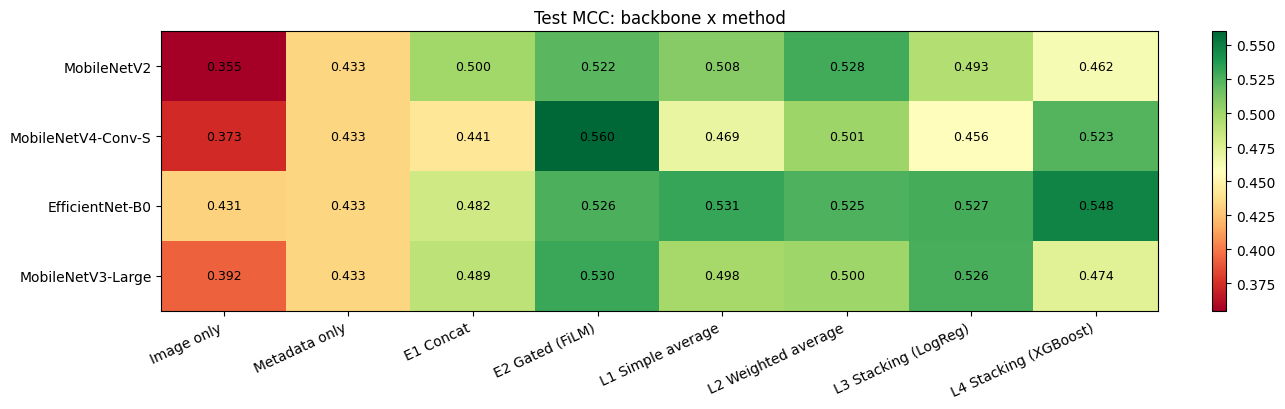

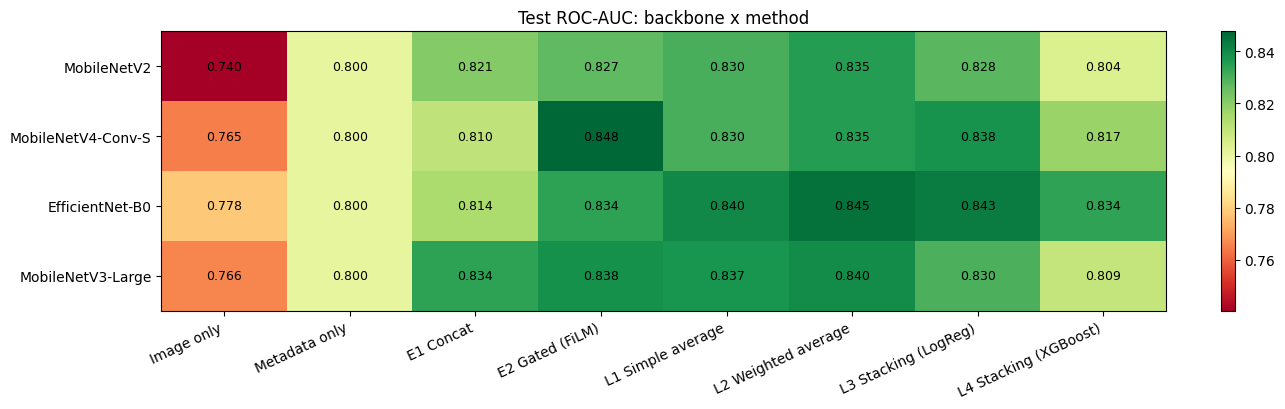

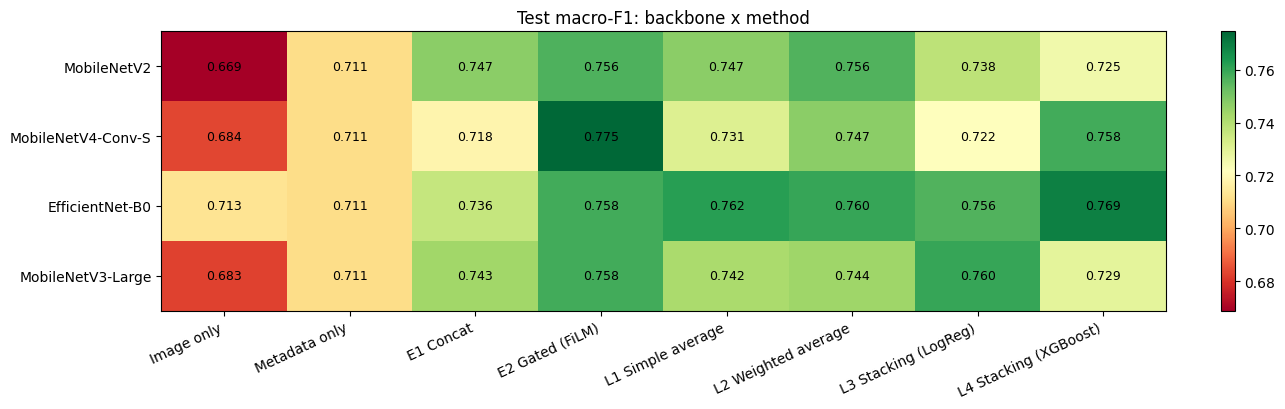

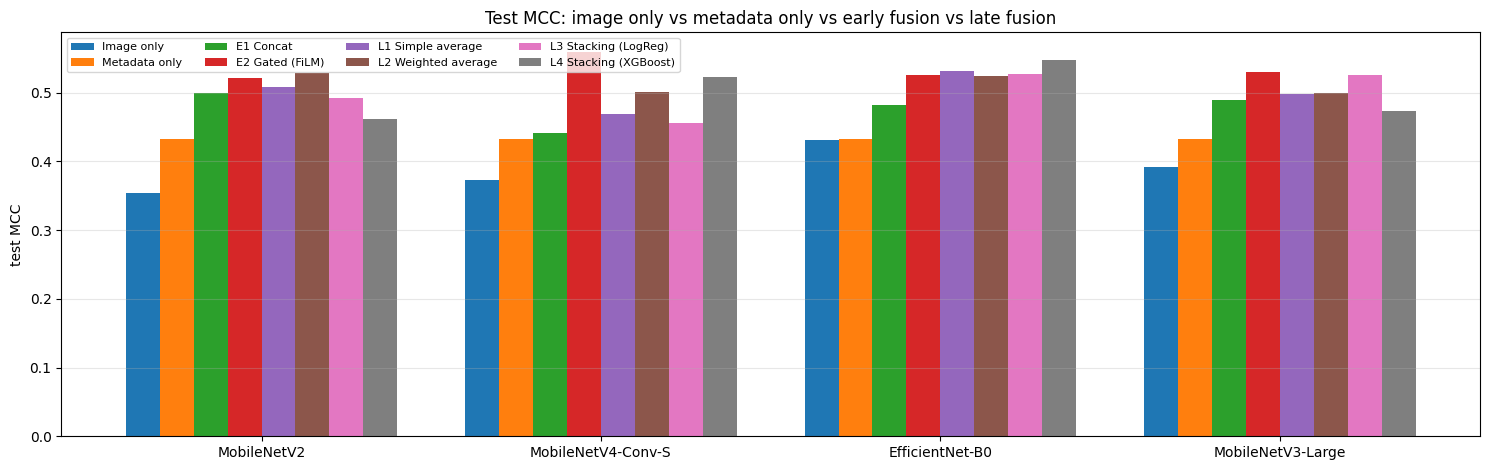

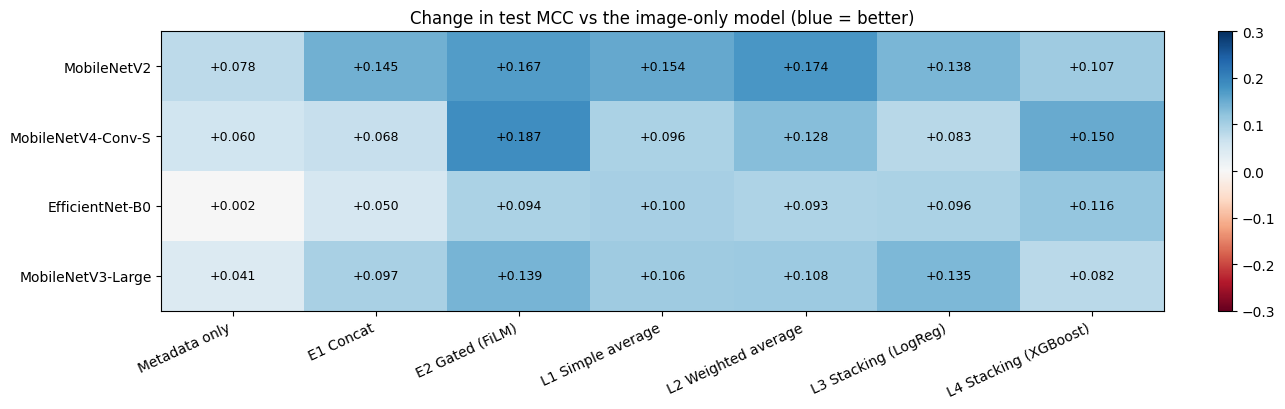

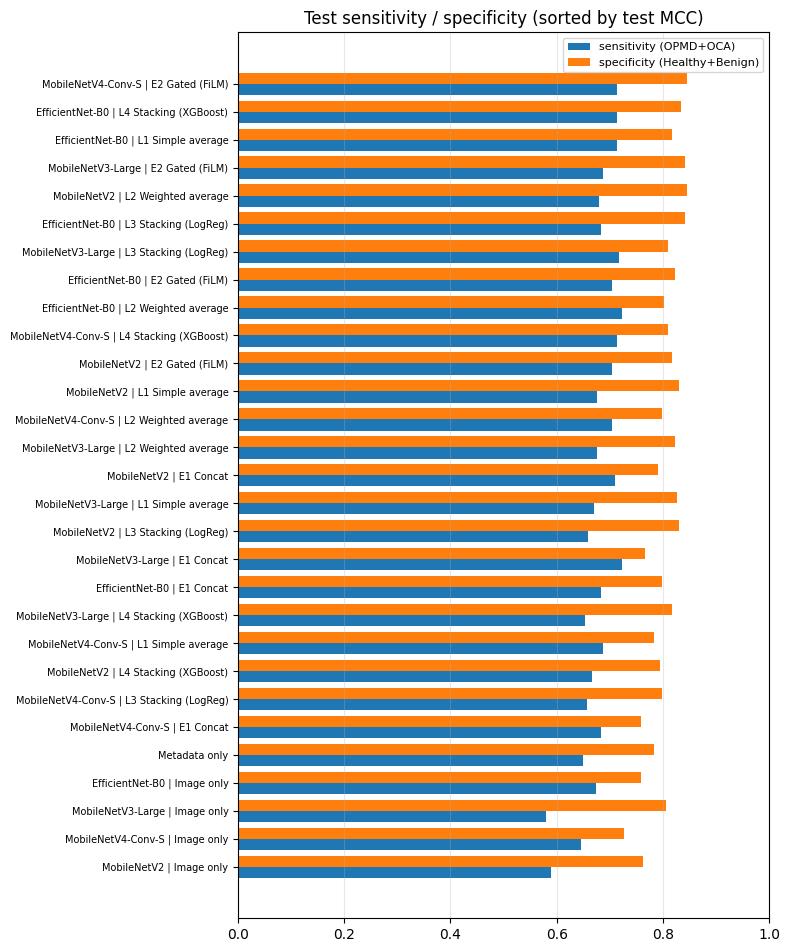

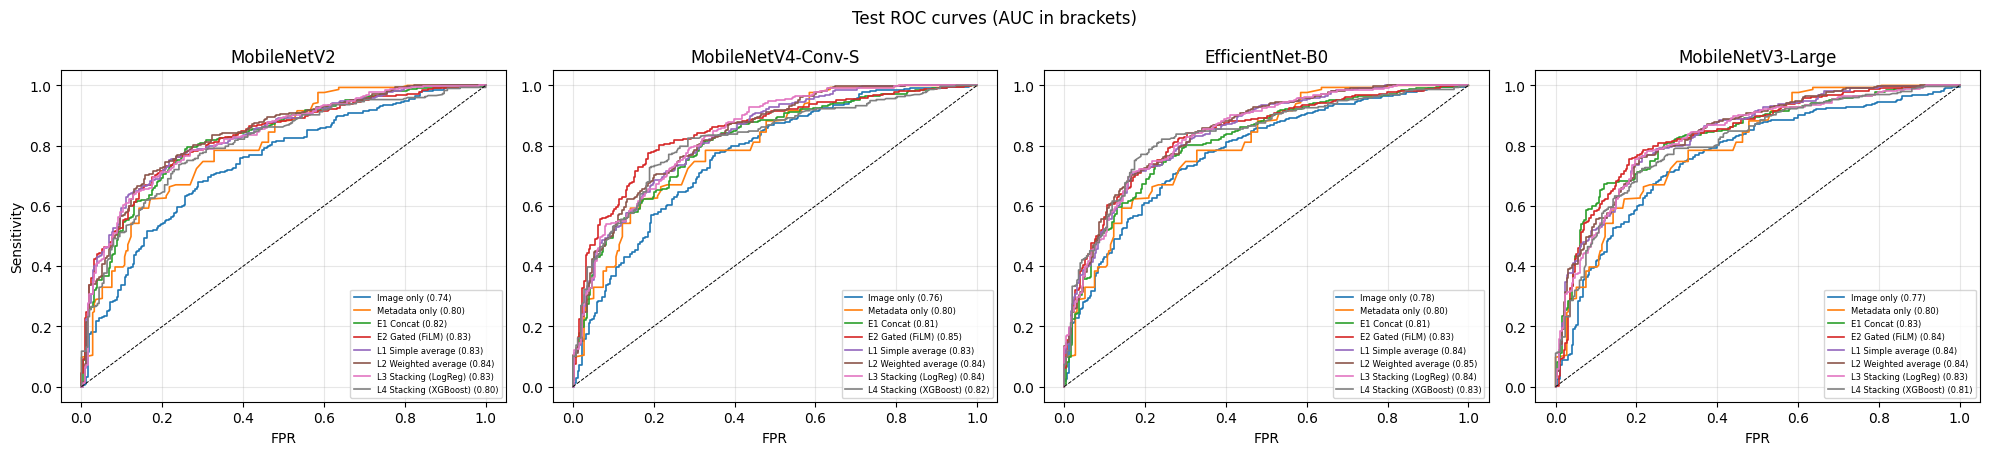

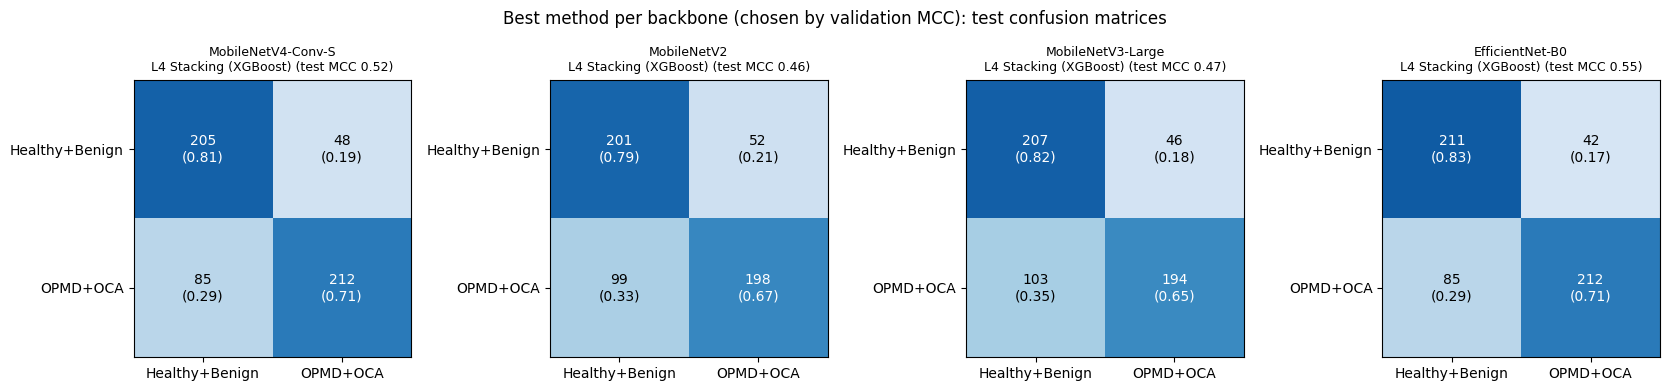

,test_Healthy_correct,test_Benign_correct,test_OPMD_correct,test_OCA_correct
model,,,,
MobileNetV4-Conv-S | L4 Stacking (XGBoost),0.864,0.758,0.685,0.919
EfficientNet-B0 | L4 Stacking (XGBoost),0.912,0.758,0.685,0.919
MobileNetV4-Conv-S | E1 Concat,0.808,0.711,0.654,0.892
MobileNetV3-Large | E1 Concat,0.824,0.711,0.704,0.865
MobileNetV2 | E1 Concat,0.824,0.758,0.692,0.838
MobileNetV4-Conv-S | E2 Gated (FiLM),0.904,0.789,0.696,0.838
EfficientNet-B0 | E2 Gated (FiLM),0.872,0.773,0.685,0.838
MobileNetV3-Large | E2 Gated (FiLM),0.872,0.812,0.665,0.838
MobileNetV3-Large | L4 Stacking (XGBoost),0.896,0.742,0.631,0.811


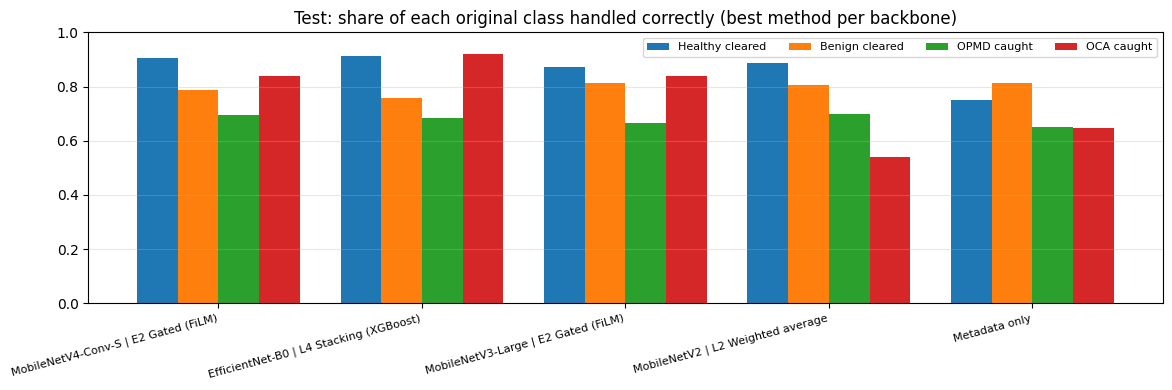

Best overall by VALIDATION MCC: MobileNetV4-Conv-S | L4 Stacking (XGBoost) -> test MCC 0.523, acc 0.758, AUC 0.817


In [9]:
R = pd.DataFrame(RESULTS)
ORDER = ["Image only", "Metadata only", "E1 Concat", "E2 Gated (FiLM)", "L1 Simple average", "L2 Weighted average",
         "L3 Stacking (LogReg)", "L4 Stacking (XGBoost)"]
bbs = [b["name"] for b in BACKBONES if b["name"] in set(R.backbone)]
meta_row = R[R.method == "Metadata only"].iloc[0]
CD = PLOT_DIR / "comparison"
pd.set_option("display.width", 250)
show = ["backbone", "method", "group", "val_mcc", "test_accuracy", "test_macro_precision", "test_macro_recall",
        "test_macro_f1", "test_mcc", "test_roc_auc", "test_sensitivity_OPMD_OCA", "test_specificity_Benign"]
display(R[show].sort_values(["backbone", "test_mcc"], ascending=[True, False]).round(3))
R.round(4).to_csv(OUT_DIR / "comparison_table.csv", index=False)


def grid(metric):
    G = pd.DataFrame(index=bbs, columns=ORDER, dtype=float)
    for _, r in R.iterrows():
        if r.method == "Metadata only":
            G.loc[:, "Metadata only"] = r[metric]
        elif r.backbone in bbs:
            G.loc[r.backbone, r.method] = r[metric]
    return G


# 1. heatmaps of test MCC and AUC
for k, (metric, title) in enumerate((("test_mcc", "Test MCC"), ("test_roc_auc", "Test ROC-AUC"), ("test_macro_f1", "Test macro-F1"))):
    G = grid(metric)
    fig, ax = plt.subplots(figsize=(13, 0.6 * len(bbs) + 1.8))
    im = ax.imshow(G.values.astype(float), cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER, rotation=25, ha="right"); ax.set_yticks(range(len(bbs))); ax.set_yticklabels(bbs)
    for i in range(len(bbs)):
        for j in range(len(ORDER)):
            v = G.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=.03); ax.set_title(f"{title}: backbone x method")
    plt.tight_layout(); fig.savefig(CD / f"0{2 + k}_{metric}_heatmap.png", dpi=130); plt.show()

# 2. grouped bars: test MCC per backbone and method
G = grid("test_mcc"); x = np.arange(len(bbs)); w = 0.8 / len(ORDER)
fig, ax = plt.subplots(figsize=(15, 4.8))
for k, m in enumerate(ORDER):
    ax.bar(x + (k - len(ORDER) / 2 + .5) * w, G[m], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(bbs); ax.set_ylabel("test MCC"); ax.grid(axis="y", alpha=.3); ax.legend(fontsize=8, ncol=4)
ax.set_title("Test MCC: image only vs metadata only vs early fusion vs late fusion"); plt.tight_layout()
fig.savefig(CD / "05_test_mcc_bars.png", dpi=130); plt.show()

# 3. gain over image-only
Gain = G.drop(columns=["Image only"]).sub(G["Image only"], axis=0)
fig, ax = plt.subplots(figsize=(13, 0.6 * len(bbs) + 1.8))
im = ax.imshow(Gain.values.astype(float), cmap="RdBu", vmin=-.3, vmax=.3, aspect="auto")
ax.set_xticks(range(Gain.shape[1])); ax.set_xticklabels(Gain.columns, rotation=25, ha="right"); ax.set_yticks(range(len(bbs))); ax.set_yticklabels(bbs)
for i in range(len(bbs)):
    for j in range(Gain.shape[1]):
        ax.text(j, i, f"{Gain.values[i, j]:+.3f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, fraction=.03); ax.set_title("Change in test MCC vs the image-only model (blue = better)")
plt.tight_layout(); fig.savefig(CD / "06_gain_over_image_only.png", dpi=130); plt.show()

# 4. sensitivity / specificity of every combination
Rs = R[R.method != "Metadata only"].copy(); Rs["label"] = Rs.backbone + " | " + Rs.method
Rs = pd.concat([Rs, R[R.method == "Metadata only"].assign(label="Metadata only")]).sort_values("test_mcc")
fig, ax = plt.subplots(figsize=(8, 0.28 * len(Rs) + 1.5))
yy = np.arange(len(Rs))
ax.barh(yy - .2, Rs.test_sensitivity_OPMD_OCA, .4, label="sensitivity (OPMD+OCA)"); ax.barh(yy + .2, Rs.test_specificity_Benign, .4, label="specificity (Healthy+Benign)")
ax.set_yticks(yy); ax.set_yticklabels(Rs.label, fontsize=7); ax.set_xlim(0, 1); ax.legend(fontsize=8); ax.grid(axis="x", alpha=.3)
ax.set_title("Test sensitivity / specificity (sorted by test MCC)"); plt.tight_layout(); fig.savefig(CD / "07_sens_spec.png", dpi=130); plt.show()

# 5. ROC per backbone
fig, axes = plt.subplots(1, len(bbs), figsize=(5 * len(bbs), 4.6), squeeze=False)
for a, bb in zip(axes[0], bbs):
    for m in ORDER:
        key = ("-", m) if m == "Metadata only" else (bb, m)
        if key in PROBS:
            p = PROBS[key]["test"]; fpr, tpr, _ = roc_curve(Y["test"], p)
            a.plot(fpr, tpr, lw=1.2, label=f"{m} ({roc_auc_score(Y['test'], p):.2f})")
    a.plot([0, 1], [0, 1], "k--", lw=.7); a.set_title(bb); a.legend(fontsize=6); a.grid(alpha=.3); a.set_xlabel("FPR")
axes[0][0].set_ylabel("Sensitivity"); fig.suptitle("Test ROC curves (AUC in brackets)"); plt.tight_layout()
fig.savefig(CD / "08_roc_per_backbone.png", dpi=130); plt.show()

# 6. confusion matrices of the best method per backbone (by validation MCC)
best = R[R.backbone.isin(bbs)].sort_values("val_mcc", ascending=False).groupby("backbone").head(1)
fig, axes = plt.subplots(1, len(best), figsize=(4.2 * len(best), 3.9), squeeze=False)
for a, (_, r) in zip(axes[0], best.iterrows()):
    cm = CMS[(r.backbone, r.method, "test")]; Mn = cm / cm.sum(1, keepdims=True)
    a.imshow(Mn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}\n({Mn[i, j]:.2f})", ha="center", va="center", color="white" if Mn[i, j] > .5 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(CLASSES); a.set_yticks([0, 1]); a.set_yticklabels(CLASSES)
    a.set_title(f"{r.backbone}\n{r.method} (test MCC {r.test_mcc:.2f})", fontsize=9)
fig.suptitle("Best method per backbone (chosen by validation MCC): test confusion matrices"); plt.tight_layout()
fig.savefig(CD / "09_best_confusion.png", dpi=130); plt.show()

# 7. per original class: who is cleared / caught (test)
brk = ["test_Healthy_correct", "test_Benign_correct", "test_OPMD_correct", "test_OCA_correct"]
B = R[["backbone", "method"] + brk].copy(); B["model"] = np.where(B.backbone == "-", "Metadata only", B.backbone + " | " + B.method)
display(B.set_index("model")[brk].round(3).sort_values("test_OCA_correct", ascending=False))
best_per_bb = R.sort_values("test_mcc", ascending=False).groupby("backbone").head(1)
Bb = B.loc[best_per_bb.index]
fig, ax = plt.subplots(figsize=(12, 4)); xx = np.arange(len(Bb)); w4 = .2
for k, (col, lab) in enumerate(zip(brk, ["Healthy cleared", "Benign cleared", "OPMD caught", "OCA caught"])):
    ax.bar(xx + (k - 1.5) * w4, Bb[col], w4, label=lab)
ax.set_xticks(xx); ax.set_xticklabels(Bb.model, rotation=15, ha="right", fontsize=8); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=.3)
ax.legend(fontsize=8, ncol=4); ax.set_title("Test: share of each original class handled correctly (best method per backbone)")
plt.tight_layout(); fig.savefig(CD / "10_per_original_class.png", dpi=130); plt.show()

top = R.sort_values("val_mcc", ascending=False).iloc[0]
print(f"Best overall by VALIDATION MCC: {top.backbone} | {top.method} -> test MCC {top.test_mcc:.3f}, acc {top.test_accuracy:.3f}, AUC {top.test_roc_auc:.3f}")

## 9. Package models for download

In [10]:
(MODEL_DIR / "HOW_TO_LOAD.md").write_text("""# Loading a fusion model
Each backbone folder has `Image_only/`, `E1_Concat/`, `E2_Gated_FiLM/` (weights + config) and `late_fusion/`.
`metadata_encoding.json` describes how the metadata vector is built (min-max age, one-hot categories, same order as `features`).
To rebuild a network, copy the `FusionNet` class from the notebook, then:

    model = FusionNet(cfg["timm_id"], cfg["method"], cfg["meta_dim"])     # pretrained weights not needed
    model.load_state_dict(torch.load("best_weights.pt", map_location="cpu")); model.eval()
    prob_OPMD_OCA = model(image_tensor, metadata_vector).softmax(1)[:, 1]
""")
shutil.copy(OUT_DIR / "comparison_table.csv", MODEL_DIR / "comparison_table.csv")
shutil.make_archive(str(OUT_DIR / "models"), "zip", MODEL_DIR)
print("Download:", OUT_DIR / "models.zip", f"({(OUT_DIR / 'models.zip').stat().st_size / 1e6:.0f} MB)")

Download: /kaggle/working/metadata_fusion_optionA/models.zip (151 MB)
